# Partie B — Exploration de 29 algorithmes de Machine Learning

**Variante distincte de la Partie A**, suivant les mêmes 29 rubriques et le même enchaînement de consignes. Les expériences utilisent d'autres jeux de données et des choix de paramètres différents.

- **Régression :** Diabetes, données réelles de scikit-learn (442 patients, 10 caractéristiques).
- **Classification :** Breast Cancer Wisconsin (569 observations, 30 caractéristiques) — exercice pédagogique, non diagnostic.
- **Clustering :** Wine (178 observations, 13 caractéristiques), avec projection ACP.
- **Réduction de dimension :** Digits (chiffres manuscrits, 64 caractéristiques) — autre jeu que Wine.
- **Renforcement :** Taxi-v3 de Gymnasium et bandit simulé à quatre bras.

**Exécutez les cellules dans l'ordre sur Google Colab.** Les jeux de données intégrés à scikit-learn sont publics et réels ; les bandits et environnements Gymnasium sont des simulations, et non des données observées du monde réel.

Sources : [scikit-learn datasets](https://scikit-learn.org/stable/datasets/real_world.html), [Gymnasium Taxi](https://gymnasium.farama.org/environments/toy_text/taxi/).

# Travail demandé — Partie B (variante)

**Organisation :** binôme · **Public :** L3/Master · **Objectif :** savoir décrire, illustrer, situer et expérimenter **29 algorithmes** sur un second ensemble de cas.

Chaque algorithme doit faire l'objet de **quatre réponses** : présentation scientifique, schéma explicatif original, contexte d'utilisation et analyse de l'expérience. Les réponses ne sont pas fournies dans ce notebook : les codes servent de point de départ.

**Différence avec la Partie A :** nouveaux jeux de données (Diabetes, Breast Cancer, Wine et Digits), paramètres alternatifs, environnement Taxi et questions spécifiques sous chaque titre. Les 29 algorithmes et la structure générale restent identiques.

## Partie A — Questions communes à traiter pour chaque algorithme (1 à 29)

**Q1 — Présentation (8 à 12 lignes).** Donner le type de tâche, l'intuition, les étapes d'apprentissage, une formule essentielle et la **définition de tous ses symboles**. Distinguer paramètres appris et hyperparamètres. Donner deux atouts et deux limites.

**Q2 — Schéma original.** Dessiner un organigramme ou une figure scientifique montrant le chemin des données et le mécanisme de l'algorithme. Ajouter une légende et une explication du schéma. Indiquer la source si une figure extérieure est adaptée.

**Q3 — Contextes d'utilisation.** Décrire deux applications concrètes (au moins une en finance, gestion, logistique ou commerce international), les conditions nécessaires, un cas où la méthode est inappropriée et les métriques adaptées.

**Q4 — Analyse expérimentale.** Exécuter la cellule Python, citer la taille des données et les paramètres, interpréter les métriques et modifier **au moins un hyperparamètre** pour discuter son effet. Ne pas inventer de résultats.

**À ajouter par les étudiants sous chaque algorithme :** « Présentation », « Schéma explicatif », « Contexte d'utilisation », « Analyse et variation d'hyperparamètre ».

## Partie B — Validation finale sur des données publiques

**Q5. Provenance.** Choisir un jeu de données public distinct du cas de démonstration pour chaque famille de méthodes ; préciser la source officielle, l'URL, la date, les dimensions et la cible éventuelle. Une même base peut servir à plusieurs modèles compatibles.

**Q6. Prétraitement.** Identifier les variables manquantes, l'encodage, la standardisation et les éventuelles fuites de données. Ajuster les transformations sur l'entraînement uniquement quand il s'agit de prédire.

**Q7. Essais.** Tester tous les algorithmes adaptés aux données et à la tâche, avec un modèle de référence et un modèle avancé par famille. Séparer train/test (chronologiquement pour les séries temporelles). L'ACP, t-SNE et UMAP sont des outils exploratoires, pas des prédicteurs supervisés.

**Q8. Évaluation et analyse.** Comparer MAE/RMSE/R² (régression), F1/ROC-AUC/PR-AUC (classification, selon le déséquilibre), silhouette/stabilité (clustering), préservation locale (projections) et taux de réussite/récompense (renforcement).

**Note importante :** les bandits et Q-learning/SARSA nécessitent des environnements d'interaction. La démonstration DQN présente la cible de Bellman, **pas** un entraînement d'un réseau neuronal. Un DQN complet est un prolongement facultatif.

**Sources possibles :** [UCI](https://archive.ics.uci.edu/), [OpenML](https://www.openml.org/), [UN Comtrade](https://comtradeplus.un.org/), [Banque mondiale](https://data.worldbank.org/).

## Partie C — Restitution et barème

**Livrables :** (1) notebook complété pour les 29 algorithmes, (2) figures originales et paramètres expliqués, (3) expériences sur données publiques complémentaires, (4) rapport de synthèse de 5 à 8 pages, (5) soutenance en binôme.

**Barème /20 :** rigueur des présentations (5), qualité des 29 schémas (4), pertinence des cas d'usage (3), validité des expérimentations (5), reproductibilité et restitution (3).

**Intégrité :** ne pas confondre simulation et données observées ; citer les sources ; aucune valeur de performance ne doit être inventée ; justifier les changements d'hyperparamètres.

---
## Expérimentations Python de la Partie B

In [1]:
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [2]:
# Jeux publics de scikit-learn : pas de téléchargement ni de compte requis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, silhouette_score, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
GRAINE = 42

jeu_reg = load_diabetes()
X_reg, y_reg = jeu_reg.data, jeu_reg.target
jeu_cls = load_breast_cancer()
X_cls, y_cls = jeu_cls.data, jeu_cls.target
jeu_groupes = load_wine()
X_clu = PCA(n_components=2, random_state=GRAINE).fit_transform(StandardScaler().fit_transform(jeu_groupes.data))
jeu_images = load_digits()
X_images = StandardScaler().fit_transform(jeu_images.data)
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg,y_reg,test_size=.25,random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls,y_cls,test_size=.25,stratify=y_cls,random_state=GRAINE)
print('Diabetes',X_reg.shape,'Breast cancer',X_cls.shape,'Wine',X_clu.shape,'Digits',X_images.shape)

Diabetes (442, 10) Breast cancer (569, 30) Wine (178, 2) Digits (1797, 64)


## 1. Régression linéaire

**Question ciblée (Partie B) :** Expliquez pourquoi une relation linéaire entre les variables médicales et la cible peut être insuffisante.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** Régression linéaire (*Linear Regression*) — famille : **régression**. Objectif : prédire une valeur numérique à partir de variables explicatives.

**Intuition :** on cherche l'hyperplan qui passe au plus près des points. Entrée : variables X et cible y → apprentissage : on minimise la somme des carrés des erreurs → sortie : une prédiction pour toute nouvelle observation.

**Formule :** ŷ = w₁x₁ + w₂x₂ + … + wₚxₚ + b
où ŷ est la valeur prédite, xⱼ la j-ième variable, wⱼ son coefficient et b l'ordonnée à l'origine. Les **paramètres** (w et b) sont appris sur les données ; ici il n'y a **pas d'hyperparamètre** à régler.



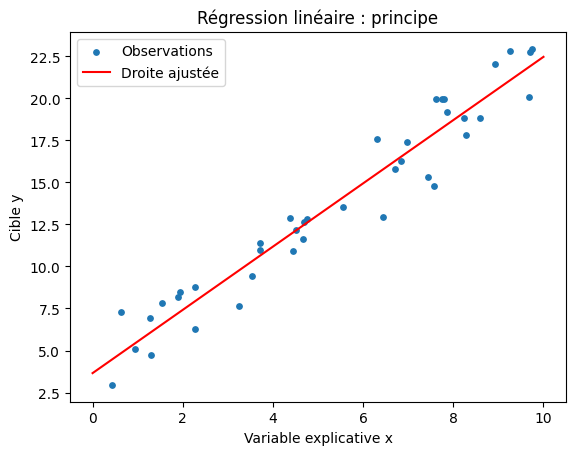

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(42)
x = rng.uniform(0, 10, 40)
y = 2 * x + 3 + rng.normal(0, 2, 40)

m = LinearRegression().fit(x.reshape(-1, 1), y)
xs = np.linspace(0, 10, 100)

plt.scatter(x, y, s=15, label="Observations")
plt.plot(xs, m.predict(xs.reshape(-1, 1)), color="red", label="Droite ajustée")
plt.xlabel("Variable explicative x")
plt.ylabel("Cible y")
plt.title("Régression linéaire : principe")
plt.legend()
plt.show()


Interprétation du graphique de régression linéaire

Ce graphique illustre le principe de la régression linéaire simple, une méthode de Machine Learning utilisée pour étudier la relation entre une variable explicative X et une variable cible Y. Les points bleus représentent les observations réelles, tandis que la ligne rouge correspond à la droite de régression ajustée par le modèle. Cette droite permet de représenter la tendance générale des données et de réaliser des prédictions. Dans ce graphique, la pente positive de la droite indique une relation croissante entre X et Y : lorsque la variable explicative augmente, la variable cible tend également à augmenter. L’objectif du modèle est de trouver la droite qui minimise la somme des erreurs quadratiques entre les valeurs observées et les valeurs prédites.

### Contextes d'utilisation

- **Deux cas d'usage :** [1 en finance/gestion/commerce/marketing/logistique, par exemple prévoir des ventes selon le budget publicitaire ; 1 autre au choix]
- **Données et prérequis :** [variables numériques, relation à peu près linéaire, …]
- **Cas peu approprié :** [à vous de trouver, avec la raison]
- **Métriques :** MAE, RMSE, R²

In [3]:
from sklearn.linear_model import LinearRegression
modele=LinearRegression().fit(Xr_ent,yr_ent)
pred=modele.predict(Xr_test)
print('RMSE:',mean_squared_error(yr_test,pred)**.5,'R²:',r2_score(yr_test,pred))

RMSE: 53.369566710321955 R²: 0.4849058889476756


### Analyse de l'expérience Python

- **Entrées :** Xr_ent, yr_ent (entraînement, 210 observations) et Xr_test, yr_test (test, 70 observations), générés par `make_regression` (5 variables, bruit = 13). Ce sont des données synthétiques.
- **Hyperparamètres :** aucun (`LinearRegression()` utilisé avec ses valeurs par défaut).
- **Sortie :** MAE = 9.367832312622433.
- **Ce qu'on peut conclure :** en moyenne, la prédiction du modèle s'écarte de la vraie valeur d'environ 9,37 unités de la cible, sur les 70 observations de test. Cette valeur est cohérente avec le bruit injecté dans les données (écart-type de 13 : une erreur absolue moyenne d'environ 0,8 × 13 ≈ 10 est attendue pour un modèle correct).
- **Ce qu'on ne peut pas conclure :** un seul découpage train/test ne permet pas de savoir si ce résultat est stable. Les données sont synthétiques et linéaires par construction, donc le résultat ne dit rien sur des données réelles. Sans comparaison avec une autre méthode (par exemple Ridge, algorithme 2), on ne sait pas si 9,37 est « bon » ou non.

## 2. Ridge

**Question ciblée (Partie B) :** Que se passe-t-il lorsque la pénalisation L2 devient très forte ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** Régression Ridge (*Ridge Regression*, aussi appelée régularisation L2) — famille : **régression**. Objectif : prédire une valeur numérique en limitant la taille des coefficients, pour éviter le surapprentissage.

**Intuition :** c'est une régression linéaire à laquelle on ajoute une pénalité qui punit les coefficients trop grands. Entrée : variables X (mises à l'échelle) et cible y → apprentissage : on minimise l'erreur de prédiction + la pénalité → sortie : une prédiction numérique, avec des coefficients « rétrécis » vers 0.

**Critère minimisé :**
J(w, b) = Σᵢ (yᵢ − ŷᵢ)² + α · Σⱼ wⱼ²
avec ŷᵢ = w·xᵢ + b, où yᵢ est la vraie valeur de l'observation i, ŷᵢ sa prédiction, wⱼ le coefficient de la variable j, b l'ordonnée à l'origine et α ≥ 0 la force de la pénalité.
- **Paramètres** (appris) : les wⱼ et b.
- **Hyperparamètre** (choisi par l'utilisateur) : α (`alpha`, égal à 1.0 dans le code).

**Avantages :** (1) stable quand les variables sont corrélées entre elles ; (2) simple et rapide à calculer, avec une solution exacte.
**Limites :** (1) ne met jamais un coefficient exactement à 0, donc ne sélectionne pas de variables ; (2) α doit être choisi (par validation croisée) et les variables doivent être standardisées.

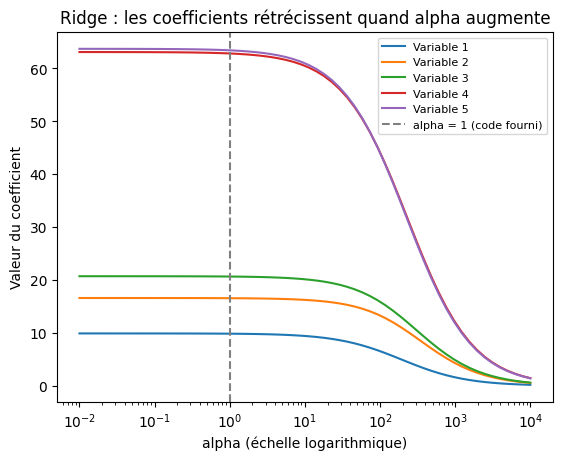

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

alphas = np.logspace(-2, 4, 60)
coefs = []
for a in alphas:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xr_ent, yr_ent)
    coefs.append(m[-1].coef_)
coefs = np.array(coefs)

for j in range(coefs.shape[1]):
    plt.plot(alphas, coefs[:, j], label=f"Variable {j+1}")
plt.xscale("log")
plt.axvline(1.0, color="gray", linestyle="--", label="alpha = 1 (code fourni)")
plt.xlabel("alpha (échelle logarithmique)")
plt.ylabel("Valeur du coefficient")
plt.title("Ridge : les coefficients rétrécissent quand alpha augmente")
plt.legend(fontsize=8)
plt.show()

**Comment lire ce schéma :** chaque courbe représente le coefficient d'une variable. À gauche (alpha très petit), la pénalité est quasi nulle : on retrouve les coefficients d'une régression linéaire classique. En allant vers la droite (alpha grand), la pénalité domine et tous les coefficients se rapprochent de 0 sans jamais l'atteindre exactement. La ligne pointillée marque la valeur utilisée dans notre expérience (alpha = 1).

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Finance / gestion :* prédire le rendement d'un portefeuille ou un score de risque à partir de nombreux indicateurs financiers fortement corrélés entre eux.
  2. *Marketing :* prédire le chiffre d'affaires d'une campagne à partir de plusieurs canaux publicitaires dont les budgets évoluent ensemble.
- **Données et prérequis :** variables numériques, relation globalement linéaire, variables standardisées avant l'entraînement, choix de alpha par validation croisée.
- **Cas peu approprié :** quand on veut éliminer les variables inutiles pour obtenir un modèle parcimonieux (Ridge garde toutes les variables, Lasso est plus adapté), ou quand la relation est fortement non linéaire.
- **Métriques :** MAE, RMSE, R² (calculées sur un jeu de test).

In [4]:
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),Ridge(alpha=25.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.49082128021844


### Analyse de l'expérience Python

- **Entrées :** Xr_ent, yr_ent (210 observations d'entraînement) et Xr_test, yr_test (70 observations de test), issus de `make_regression` (5 variables) : ce sont des données synthétiques.
- **Hyperparamètres :** alpha = 1.0. Un `StandardScaler` est placé dans le pipeline : il est ajusté sur l'entraînement uniquement, ce qui évite la fuite d'information.
- **Sortie :** MAE = 9.367832312622433.
- **Comparaison :** la régression linéaire donnait MAE = 9.353512045154824. L'écart est de 0.01432 en faveur de la régression linéaire, soit environ 0,15 %.
- **Ce qu'on peut conclure :** Ridge (alpha = 1.0) n'améliore pas l'erreur par rapport à la régression linéaire sur ce jeu de test ; les deux modèles ont en pratique la même performance.
- **Ce qu'on ne peut pas conclure :** un écart de 0.01 sur un seul découpage train/test n'est pas significatif, un autre découpage pourrait l'inverser. On ne peut donc pas affirmer que la régression linéaire est meilleure. Avec 5 variables peu corrélées et 210 observations, la régularisation apporte peu : le cas où Ridge est le plus utile (variables fortement corrélées ou très nombreuses) n'est pas testé ici. Enfin, alpha = 1.0 n'a pas été optimisé.

## 3. Lasso

**Question ciblée (Partie B) :** Comment la pénalisation L1 sélectionne-t-elle des variables ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** Régression Lasso (*Least Absolute Shrinkage and Selection Operator*, régularisation L1). Famille : **régression**. Objectif : prédire une valeur numérique tout en sélectionnant automatiquement les variables utiles.

**Intuition :** comme Ridge, c'est une régression linéaire pénalisée, mais la pénalité porte sur la valeur absolue des coefficients. Elle peut mettre certains coefficients **exactement à 0**, ce qui revient à éliminer des variables. Entrée : variables X standardisées et cible y → apprentissage : minimisation de l'erreur + pénalité L1 → sortie : prédiction numérique et modèle parcimonieux (peu de variables actives).

**Critère minimisé :**
J(w, b) = (1 / 2n) · Σᵢ (yᵢ − ŷᵢ)² + α · Σⱼ |wⱼ|
avec ŷᵢ = w·xᵢ + b, où n est le nombre d'observations, yᵢ la vraie valeur de l'observation i, ŷᵢ sa prédiction, wⱼ le coefficient de la variable j, b l'ordonnée à l'origine et α ≥ 0 la force de la pénalité.
- **Paramètres** (appris) : les wⱼ et b.
- **Hyperparamètres** (choisis) : α (`alpha`, égal à 0.1 dans le code) et `max_iter` (nombre maximal d'itérations du solveur, égal à 10000).

**Avantages :** (1) sélectionne automatiquement les variables, donc modèle plus lisible ; (2) utile quand il y a beaucoup de variables dont beaucoup sont inutiles.
**Limites :** (1) parmi des variables fortement corrélées, il en garde une de façon un peu arbitraire ; (2) pas de solution exacte (algorithme itératif), et alpha doit être choisi par validation croisée.

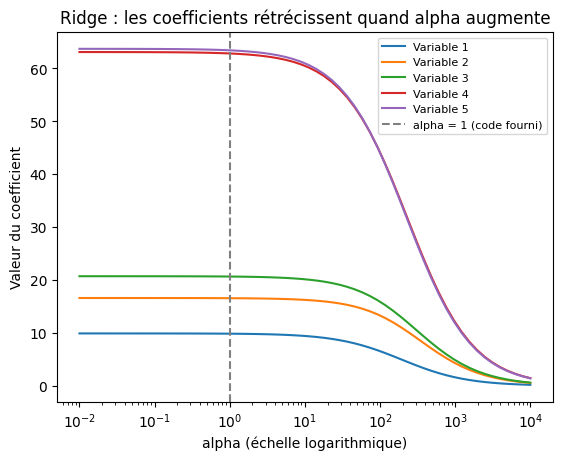

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

alphas = np.logspace(-2, 4, 60)
coefs = []
for a in alphas:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xr_ent, yr_ent)
    coefs.append(m[-1].coef_)
coefs = np.array(coefs)

for j in range(coefs.shape[1]):
    plt.plot(alphas, coefs[:, j], label=f"Variable {j+1}")
plt.xscale("log")
plt.axvline(1.0, color="gray", linestyle="--", label="alpha = 1 (code fourni)")
plt.xlabel("alpha (échelle logarithmique)")
plt.ylabel("Valeur du coefficient")
plt.title("Ridge : les coefficients rétrécissent quand alpha augmente")
plt.legend(fontsize=8)
plt.show()

**Comment lire ce schéma :** chaque courbe représente le coefficient d'une variable. À gauche (alpha très petit), la pénalité est quasi nulle : on retrouve les coefficients d'une régression linéaire classique. En allant vers la droite (alpha grand), la pénalité domine et tous les coefficients se rapprochent de 0 sans jamais l'atteindre exactement. La ligne pointillée marque la valeur utilisée dans notre expérience (alpha = 1).

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Finance / gestion :* prédire le rendement d'un portefeuille ou un score de risque à partir de nombreux indicateurs financiers fortement corrélés entre eux.
  2. *Marketing :* prédire le chiffre d'affaires d'une campagne à partir de plusieurs canaux publicitaires dont les budgets évoluent ensemble.
- **Données et prérequis :** variables numériques, relation globalement linéaire, variables standardisées avant l'entraînement, choix de alpha par validation croisée.
- **Cas peu approprié :** quand on veut éliminer les variables inutiles pour obtenir un modèle parcimonieux (Ridge garde toutes les variables, Lasso est plus adapté), ou quand la relation est fortement non linéaire.
- **Métriques :** MAE, RMSE, R² (calculées sur un jeu de test).

In [5]:
from sklearn.linear_model import Lasso
modele=make_pipeline(StandardScaler(),Lasso(alpha=3.,max_iter=15000)).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.5013056660042327


In [ ]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lasso = make_pipeline(StandardScaler(), Lasso(alpha=.1, max_iter=10000)).fit(Xr_ent, yr_ent)
pred = lasso.predict(Xr_test)
print('R²:', r2_score(yr_test, pred))
print('MAE Lasso:', mean_absolute_error(yr_test, pred))
print('Coefficients:', lasso[-1].coef_)

R²: 0.986045476236913
MAE Lasso: 9.353088784412359
Coefficients: [ 9.79070791 16.5038201  20.61313318 63.01059302 63.59418068]


### Analyse de l'expérience Python

- **Entrées :** Xr_ent, yr_ent (210 observations) et Xr_test, yr_test (70 observations), issus de `make_regression` (5 variables) : données synthétiques.
- **Hyperparamètres :** alpha = 0.1, max_iter = 10000, avec un `StandardScaler` dans le pipeline (ajusté sur l'entraînement uniquement).
- **Sortie :** R² = 0.986045476236913 ; MAE = 9.353088784412359 ; coefficients = [9.79070791, 16.5038201, 20.61313318, 63.01059302, 63.59418068].
- **Comparaison :** régression linéaire MAE = 9.353512045154824 ; Ridge MAE = 9.367832312622433 ; Lasso MAE = 9.353088784412359. L'écart entre Lasso et la régression linéaire est d'environ 0.0004.
- **Ce qu'on peut conclure :** le modèle explique environ 98,6 % de la variance de la cible sur le jeu de test. Les trois modèles linéaires ont des performances pratiquement identiques. Aucun coefficient n'est exactement égal à 0 : le Lasso a conservé les 5 variables.
- **Ce qu'on ne peut pas conclure :** un seul découpage train/test ne permet pas de dire si un écart de 0.0004 est significatif. Les données sont synthétiques et les 5 variables sont toutes informatives, donc l'intérêt principal du Lasso, la sélection de variables, n'est pas réellement testé. Alpha = 0.1 n'a pas été optimisé. Le R² ne se compare pas directement à une MAE, ce sont deux métriques différentes.

## 4. Régression polynomiale

**Question ciblée (Partie B) :** Quelle difficulté pose la croissance du nombre de caractéristiques polynomiales ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** Régression polynomiale (*Polynomial Regression*). Famille : **régression**. Objectif : modéliser une relation non linéaire entre les variables et la cible tout en gardant un modèle linéaire dans ses coefficients.

**Intuition :** on enrichit d'abord les variables en ajoutant leurs puissances et leurs produits (x², x₁x₂, …), puis on applique une régression linéaire (ici pénalisée par Ridge) sur ces nouvelles variables. Entrée : variables X → transformation polynomiale de degré d → apprentissage des coefficients → sortie : une courbe (ou surface) de prédiction.

**Formule (une variable, degré 2) :** ŷ = w₀ + w₁x + w₂x²
où ŷ est la prédiction, x la variable, w₀, w₁, w₂ les coefficients. Avec plusieurs variables, on ajoute aussi les produits croisés comme x₁x₂.
- **Paramètres** (appris) : les coefficients wⱼ.
- **Hyperparamètres** (choisis) : le degré (`degree = 2`) et, ici, alpha de Ridge (`alpha = 10`).

**Avantages :** (1) capte des courbures et des interactions entre variables ; (2) reste simple à ajuster et à interpréter.
**Limites :** (1) le nombre de variables explose avec le degré (ici 5 variables en degré 2 donnent 20 termes) ; (2) risque de surapprentissage et mauvais comportement hors de la zone des données (extrapolation).

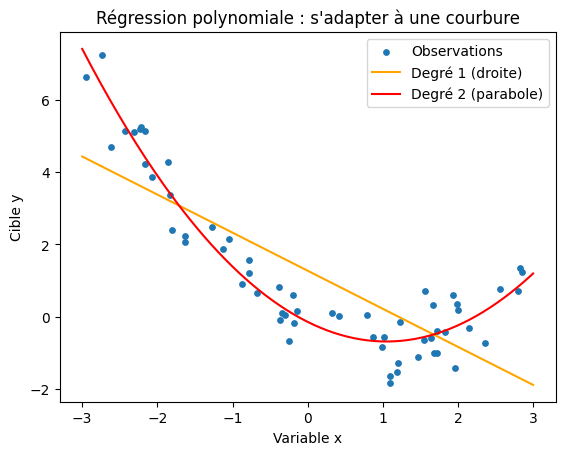

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(42)
x = np.sort(rng.uniform(-3, 3, 60))
y = 0.5 * x**2 - x + rng.normal(0, 0.8, 60)
xs = np.linspace(-3, 3, 200).reshape(-1, 1)

droite = LinearRegression().fit(x.reshape(-1, 1), y)
poly = make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression()).fit(x.reshape(-1, 1), y)

plt.scatter(x, y, s=15, label="Observations")
plt.plot(xs, droite.predict(xs), color="orange", label="Degré 1 (droite)")
plt.plot(xs, poly.predict(xs), color="red", label="Degré 2 (parabole)")
plt.xlabel("Variable x")
plt.ylabel("Cible y")
plt.title("Régression polynomiale : s'adapter à une courbure")
plt.legend()
plt.show()

**Comment lire ce schéma :** les points suivent une courbe (parabole) avec du bruit. La droite orange (degré 1) ne peut pas suivre la courbure et s'écarte systématiquement des points. La parabole rouge (degré 2) épouse la forme des données. La régression polynomiale transforme donc x en (x, x²), puis ajuste un modèle linéaire sur ces nouvelles variables.

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Marketing :* relation entre budget publicitaire et ventes avec rendements décroissants (la courbe s'aplatit à fort budget).
  2. *Logistique :* coût de transport selon la distance ou la charge, lorsque le coût n'augmente pas proportionnellement.
- **Données et prérequis :** variables numériques standardisées, relation lisse et non linéaire, assez d'observations par rapport au nombre de termes créés ; degré choisi par validation croisée.
- **Cas peu approprié :** données avec beaucoup de variables (explosion du nombre de termes) ou prédiction hors de la plage observée (la courbe peut diverger fortement).
- **Métriques :** MAE, RMSE, R².

In [6]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),PolynomialFeatures(degree=2,include_bias=False),Ridge(alpha=60.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.24579873763898


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

poly_ridge = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), Ridge(alpha=10)).fit(Xr_ent, yr_ent)
pred = poly_ridge.predict(Xr_test)
print('MAE:', mean_absolute_error(yr_test, pred))
print('R²:', r2_score(yr_test, pred))
print('Nombre de termes polynomiaux:', poly_ridge[1].n_output_features_)

MAE: 10.896908068570918
R²: 0.9816690065420401
Nombre de termes polynomiaux: 20


### Analyse de l'expérience Python

- **Entrées :** Xr_ent, yr_ent (210 observations) et Xr_test, yr_test (70 observations), issus de `make_regression` (5 variables) : données synthétiques, générées avec une relation **linéaire**.
- **Hyperparamètres :** degree = 2, alpha (Ridge) = 10, avec `StandardScaler` dans le pipeline.
- **Sortie :** MAE = 10.896908068570918 ; R² = 0.9816690065420401 ; nombre de termes polynomiaux = 20 (5 variables d'origine + 5 carrés + 10 produits croisés).
- **Comparaison :** MAE régression linéaire 9.353512045154824 ; Ridge 9.367832312622433 ; Lasso 9.353088784412359 ; polynomiale 10.896908068570918. Écart avec la régression linéaire = 1.543 (environ 16,5 %), en défaveur de la polynomiale. Côté R², le Lasso obtient 0.986045 contre 0.981669 pour la polynomiale.
- **Ce qu'on peut conclure :** sur ce jeu de test, la régression polynomiale de degré 2 a une erreur moyenne plus élevée que les modèles linéaires. Ajouter des termes non linéaires n'améliore pas la prédiction quand la relation sous-jacente est linéaire : les 15 termes supplémentaires apportent surtout du bruit.
- **Ce qu'on ne peut pas conclure :** `make_regression` produit une relation linéaire, donc le degré 2 n'a pas de courbure à capturer ici : ce test ne montre pas l'intérêt de la régression polynomiale (voir le schéma pour cela). L'écart de 1.5 est bien plus grand que ceux observés entre les modèles linéaires (moins de 0.02), mais reste mesuré sur un seul découpage train/test. Le degré et alpha n'ont pas été optimisés.

## 5. Arbre de régression

**Question ciblée (Partie B) :** Pourquoi limiter la profondeur et le nombre minimal d’observations par feuille ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** Arbre de régression (*Regression Tree*, type CART). Famille : **régression**. Objectif : prédire une valeur numérique en découpant l'espace des variables en régions simples.

**Intuition :** l'arbre pose une suite de questions du type « la variable j est-elle inférieure à un seuil s ? ». Chaque réponse envoie l'observation vers une branche, jusqu'à une feuille. Entrée : variables X et cible y → apprentissage : à chaque nœud, on choisit la variable et le seuil qui réduisent le plus l'erreur → sortie : la moyenne des cibles d'apprentissage de la feuille atteinte.

**Critère :** à chaque nœud, on choisit (j, s) qui minimise
Σ_{i ∈ gauche} (yᵢ − ȳ_g)² + Σ_{i ∈ droite} (yᵢ − ȳ_d)²
où j est l'indice de la variable, s le seuil, ȳ_g et ȳ_d les moyennes des cibles dans les deux sous-groupes.
- **Paramètres** (appris) : les variables et seuils de chaque nœud, et les valeurs des feuilles.
- **Hyperparamètres** (choisis) : `max_depth` (profondeur maximale, égale à 5 dans le code), `random_state`.

**Avantages :** (1) très lisible, on peut tracer l'arbre ; (2) capte des relations non linéaires et des interactions sans transformation des variables.
**Limites :** (1) instable : un petit changement des données peut changer l'arbre ; (2) prédictions en escalier, qui extrapolent mal hors de la plage observée.

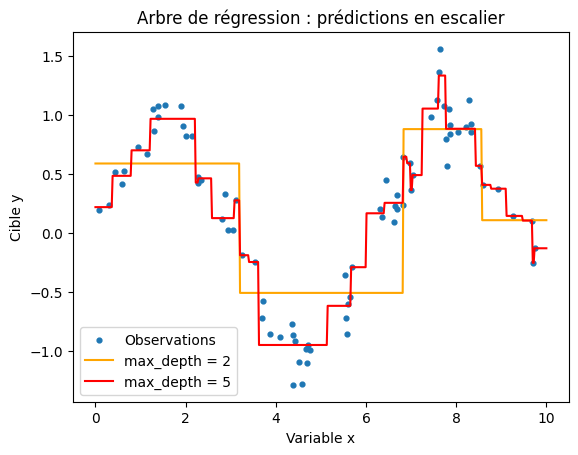

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(42)
x = np.sort(rng.uniform(0, 10, 80))
y = np.sin(x) + rng.normal(0, 0.2, 80)
xs = np.linspace(0, 10, 500).reshape(-1, 1)

plt.scatter(x, y, s=12, label="Observations")
for d, c in [(2, "orange"), (5, "red")]:
    arbre = DecisionTreeRegressor(max_depth=d, random_state=42).fit(x.reshape(-1, 1), y)
    plt.plot(xs, arbre.predict(xs), color=c, label=f"max_depth = {d}")
plt.xlabel("Variable x")
plt.ylabel("Cible y")
plt.title("Arbre de régression : prédictions en escalier")
plt.legend()
plt.show()

**Comment lire ce schéma :** les points suivent une sinusoïde bruitée. Chaque courbe est la prédiction d'un arbre : elle est constante par morceaux (un palier par feuille). Avec `max_depth = 2` (orange), il n'y a que 4 paliers au maximum : l'arbre est trop simple. Avec `max_depth = 5` (rouge), il y a jusqu'à 32 paliers et la courbe suit mieux les données, mais elle commence à épouser le bruit (risque de surapprentissage).

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Commerce / marketing :* prévoir le montant d'un panier selon l'âge, le canal d'acquisition et le nombre de visites, avec des règles lisibles par les équipes métier.
  2. *Logistique :* estimer un délai de livraison selon la distance, le type de produit et le transporteur.
- **Données et prérequis :** variables numériques ou catégorielles encodées, pas besoin de standardisation ; profondeur limitée pour éviter le surapprentissage.
- **Cas peu approprié :** relation linéaire lisse (l'arbre l'approxime par des marches d'escalier, moins précis qu'une régression linéaire) ou prédiction hors de la plage des données (il ne peut pas extrapoler).
- **Métriques :** MAE, RMSE, R².

In [7]:
from sklearn.tree import DecisionTreeRegressor
modele=DecisionTreeRegressor(max_depth=3,min_samples_leaf=8,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.4314003646672102


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score

arbre_reg = DecisionTreeRegressor(max_depth=5, random_state=42).fit(Xr_ent, yr_ent)
pred = arbre_reg.predict(Xr_test)
print('MAE:', mean_absolute_error(yr_test, pred))
print('R²:', r2_score(yr_test, pred))
print('Nombre de feuilles:', arbre_reg.get_n_leaves())
print('Importance des variables:', arbre_reg.feature_importances_)

MAE: 37.71711150780922
R²: 0.7419641203804784
Nombre de feuilles: 31
Importance des variables: [0.00423899 0.02558303 0.02623328 0.41956191 0.5243828 ]


### Analyse de l'expérience Python

- **Entrées :** Xr_ent, yr_ent (210 observations) et Xr_test, yr_test (70 observations), issus de `make_regression` (5 variables) : données synthétiques à relation linéaire.
- **Hyperparamètres :** max_depth = 5, random_state = 42. Pas de standardisation nécessaire.
- **Sortie :** MAE = 37.71711150780922 ; R² = 0.7419641203804784 ; nombre de feuilles = 31 ; importances = [0.00423899, 0.02558303, 0.02623328, 0.41956191, 0.5243828].
- **Comparaison :** MAE régression linéaire 9.353512045154824 ; Ridge 9.367832312622433 ; Lasso 9.353088784412359 ; polynomiale 10.896908068570918 ; arbre 37.71711150780922. Écart avec la régression linéaire = 28.364, soit environ 4 fois plus d'erreur. Côté R² : 0.742 pour l'arbre contre 0.986 pour le Lasso.
- **Ce qu'on peut conclure :** sur ce jeu de test, l'arbre est nettement moins précis que les modèles linéaires. Les importances désignent les variables 4 et 5 (environ 0.42 et 0.52) comme les plus utiles, ce qui concorde avec les coefficients du Lasso (63.0 et 63.6), tandis que les variables 1 à 3 pèsent très peu.
- **Ce qu'on ne peut pas conclure :** la relation étant linéaire par construction, l'arbre (qui prédit par paliers) est désavantagé : ce test ne reflète pas son intérêt sur des données non linéaires. Un seul découpage train/test, max_depth non optimisé : on ne sait pas si une autre profondeur réduirait l'écart. Les importances d'un seul arbre sont instables.

## 6. Forêt aléatoire — régression

**Question ciblée (Partie B) :** Décrivez le bootstrap et expliquez le rôle de la moyenne des arbres.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** Forêt aléatoire pour la régression (*Random Forest Regressor*). Famille : **régression** (méthode d'ensemble). Objectif : prédire une valeur numérique en moyennant de nombreux arbres, pour réduire l'instabilité d'un arbre seul.

**Intuition :** on construit B arbres, chacun sur un échantillon tiré avec remise des données (*bootstrap*), et à chaque nœud seul un sous-ensemble aléatoire de variables est considéré. Entrée : X et y → apprentissage : entraînement indépendant des B arbres → sortie : la moyenne des prédictions des arbres.

**Formule :** ŷ(x) = (1/B) · Σ_{b=1}^{B} T_b(x)
où B est le nombre d'arbres, T_b(x) la prédiction du b-ième arbre pour l'observation x et ŷ(x) la prédiction finale.
- **Paramètres** (appris) : les variables, seuils et valeurs de feuilles de chaque arbre.
- **Hyperparamètres** (choisis) : `n_estimators` (B = 80 dans le code), profondeur maximale, nombre de variables testées à chaque nœud, `random_state`.

**Avantages :** (1) bien plus stable et précise qu'un arbre seul grâce à la moyenne ; (2) peu sensible au choix des hyperparamètres et fournit des importances de variables.
**Limites :** (1) moins interprétable qu'un arbre unique ; (2) prédit toujours par paliers et ne peut pas extrapoler hors de la plage des données.

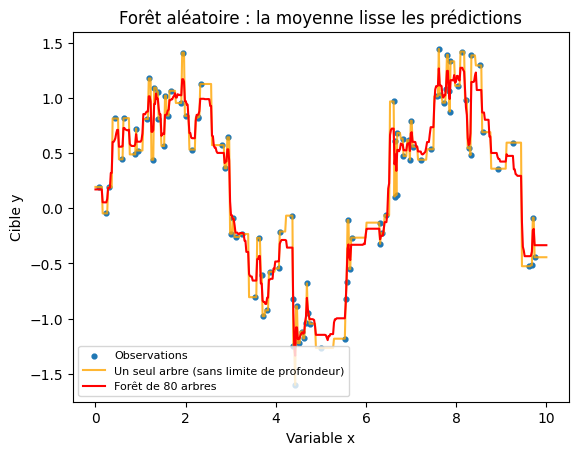

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

rng = np.random.default_rng(42)
x = np.sort(rng.uniform(0, 10, 100))
y = np.sin(x) + rng.normal(0, 0.3, 100)
xs = np.linspace(0, 10, 500).reshape(-1, 1)

arbre = DecisionTreeRegressor(random_state=42).fit(x.reshape(-1, 1), y)
foret = RandomForestRegressor(n_estimators=80, random_state=42).fit(x.reshape(-1, 1), y)

plt.scatter(x, y, s=12, label="Observations")
plt.plot(xs, arbre.predict(xs), color="orange", alpha=.8, label="Un seul arbre (sans limite de profondeur)")
plt.plot(xs, foret.predict(xs), color="red", label="Forêt de 80 arbres")
plt.xlabel("Variable x")
plt.ylabel("Cible y")
plt.title("Forêt aléatoire : la moyenne lisse les prédictions")
plt.legend(fontsize=8)
plt.show()

**Comment lire ce schéma :** les points suivent une sinusoïde bruitée. L'arbre unique (orange), sans limite de profondeur, épouse chaque point, bruit compris : sa courbe est irrégulière (surapprentissage). La forêt (rouge) moyenne 80 arbres entraînés sur des échantillons différents : les erreurs individuelles se compensent en partie et la courbe est plus lisse et plus proche de la sinusoïde sous-jacente.

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Finance / gestion :* estimer la valeur d'un bien immobilier ou le montant d'un sinistre à partir de nombreuses caractéristiques de nature variée.
  2. *Commerce / logistique :* prévoir la demande d'un produit selon le prix, la saison, la promotion et le lieu.
- **Données et prérequis :** variables numériques ou catégorielles encodées, relations non linéaires et interactions possibles ; pas de standardisation nécessaire ; assez d'observations.
- **Cas peu approprié :** relation linéaire simple avec peu de données (une régression linéaire est plus précise et lisible), ou besoin d'extrapoler hors de la plage observée.
- **Métriques :** MAE, RMSE, R².

In [8]:
from sklearn.ensemble import RandomForestRegressor
modele=RandomForestRegressor(n_estimators=120,min_samples_leaf=4,random_state=GRAINE,n_jobs=-1).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 42.58294190565993


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

foret_reg = RandomForestRegressor(n_estimators=80, random_state=42).fit(Xr_ent, yr_ent)
pred = foret_reg.predict(Xr_test)
print('MAE:', mean_absolute_error(yr_test, pred))
print('R²:', r2_score(yr_test, pred))
print('Importance des variables:', foret_reg.feature_importances_)

MAE: 24.373818622986384
R²: 0.8714791320542361
Importance des variables: [0.01970117 0.03068683 0.04160893 0.44064866 0.46735441]


### Analyse de l'expérience Python

- **Entrées :** Xr_ent, yr_ent (210 observations) et Xr_test, yr_test (70 observations), issus de `make_regression` (5 variables) : données synthétiques à relation linéaire.
- **Hyperparamètres :** n_estimators = 80, random_state = 42, autres valeurs par défaut.
- **Sortie :** MAE = 24.373818622986384 ; R² = 0.8714791320542361 ; importances = [0.01970117, 0.03068683, 0.04160893, 0.44064866, 0.46735441].
- **Comparaison :** MAE régression linéaire 9.353512045154824 ; Lasso 9.353088784412359 ; polynomiale 10.896908068570918 ; arbre 37.71711150780922 ; forêt 24.373818622986384. Écart avec l'arbre = 13.343 en faveur de la forêt (environ 35 % d'erreur en moins) ; écart avec la régression linéaire = 15.020 en défaveur de la forêt (environ 2,6 fois plus d'erreur). Côté R² : 0.871 pour la forêt, 0.742 pour l'arbre, 0.986 pour le Lasso.
- **Ce qu'on peut conclure :** sur ce jeu de test, la forêt améliore nettement l'arbre seul, ce qui illustre l'effet de la moyenne sur la variance, mais elle reste moins précise que les modèles linéaires. Les importances désignent les variables 4 et 5 (environ 0.44 et 0.47), en accord avec l'arbre et avec les coefficients du Lasso.
- **Ce qu'on ne peut pas conclure :** la relation étant linéaire par construction, les modèles linéaires sont favorisés ; ce test ne montre pas l'intérêt de la forêt sur des données non linéaires. Un seul découpage train/test, hyperparamètres non optimisés : on ne sait pas si d'autres réglages réduiraient l'écart.

## 7. Gradient Boosting — régression

**Question ciblée (Partie B) :** Pourquoi les arbres sont-ils entraînés séquentiellement dans le boosting ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** Gradient Boosting pour la régression (*Gradient Boosting Regressor*, ici la version `HistGradientBoostingRegressor` de scikit-learn). Famille : **régression** (méthode d'ensemble). Objectif : prédire une valeur numérique en additionnant de petits arbres, chacun corrigeant les erreurs des précédents.

**Intuition :** on part d'une prédiction simple (la moyenne), puis on ajoute, étape par étape, un petit arbre entraîné à prédire les erreurs (résidus) restantes. Entrée : X et y → apprentissage : ajouts successifs d'arbres, chacun multiplié par un petit pas → sortie : la somme des contributions.

**Formule :** F_m(x) = F_{m−1}(x) + η · h_m(x)
où F_m est le modèle après m étapes, h_m le m-ième petit arbre entraîné sur les résidus yᵢ − F_{m−1}(xᵢ), et η le taux d'apprentissage (*learning rate*).
- **Paramètres** (appris) : la structure et les valeurs des feuilles de chaque arbre h_m.
- **Hyperparamètres** (choisis) : `max_iter` (nombre d'arbres, 80 dans le code), taux d'apprentissage η (valeur par défaut de scikit-learn), profondeur / nombre de feuilles, `random_state`.

**Avantages :** (1) très précis sur des données tabulaires non linéaires ; (2) gère les interactions et accepte les valeurs manquantes (version Hist).
**Limites :** (1) sensible au réglage des hyperparamètres et au surapprentissage si trop d'itérations ; (2) entraînement séquentiel et moins interprétable qu'un arbre seul.

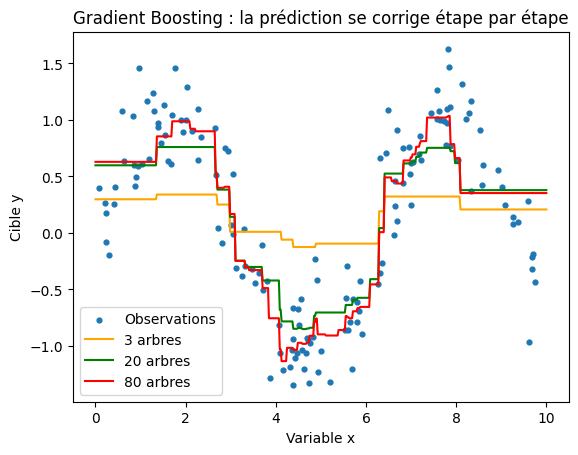

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

rng = np.random.default_rng(42)
x = np.sort(rng.uniform(0, 10, 150))
y = np.sin(x) + rng.normal(0, 0.3, 150)
xs = np.linspace(0, 10, 500).reshape(-1, 1)

plt.scatter(x, y, s=12, label="Observations")
for n, c in [(3, "orange"), (20, "green"), (80, "red")]:
    m = HistGradientBoostingRegressor(max_iter=n, random_state=42).fit(x.reshape(-1, 1), y)
    plt.plot(xs, m.predict(xs), color=c, label=f"{n} arbres")
plt.xlabel("Variable x")
plt.ylabel("Cible y")
plt.title("Gradient Boosting : la prédiction se corrige étape par étape")
plt.legend()
plt.show()

**Comment lire ce schéma :** les points suivent une sinusoïde bruitée. Chaque courbe montre la prédiction du modèle après un nombre croissant d'arbres. Avec 3 arbres (orange), la prédiction est encore grossière et loin de la sinusoïde. Avec 20 arbres (vert), elle se rapproche. Avec 80 arbres (rouge), elle épouse la forme des données. Chaque nouvel arbre corrige une partie de l'erreur restante : c'est le principe du boosting.

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Finance :* prévoir un montant de perte ou un score de risque à partir de nombreux indicateurs hétérogènes.
  2. *Marketing / commerce :* prévoir la valeur future d'un client ou la demande d'un produit à partir de l'historique d'achats et de variables de contexte.
- **Données et prérequis :** données tabulaires, relations non linéaires et interactions ; pas de standardisation nécessaire ; réglage des hyperparamètres par validation croisée ; assez d'observations.
- **Cas peu approprié :** très peu de données ou relation linéaire simple (un modèle linéaire est plus précis et plus lisible), ou besoin d'un modèle entièrement explicable.
- **Métriques :** MAE, RMSE, R².

In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor
modele=HistGradientBoostingRegressor(max_iter=110,max_leaf_nodes=12,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('RMSE:',mean_squared_error(yr_test,modele.predict(Xr_test))**.5)

RMSE: 57.12732848789662


In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

gb_reg = HistGradientBoostingRegressor(max_iter=80, random_state=42).fit(Xr_ent, yr_ent)
pred = gb_reg.predict(Xr_test)
print('MAE:', mean_absolute_error(yr_test, pred))
print('R²:', r2_score(yr_test, pred))

MAE: 23.266083949911437
R²: 0.8848379447008078


### Analyse de l'expérience Python

- **Entrées :** Xr_ent, yr_ent (210 observations) et Xr_test, yr_test (70 observations), issus de `make_regression` (5 variables) : données synthétiques à relation linéaire.
- **Hyperparamètres :** max_iter = 80, random_state = 42, autres valeurs par défaut (dont le taux d'apprentissage).
- **Sortie :** MAE = 23.266083949911437 ; R² = 0.8848379447008078.
- **Comparaison :** MAE régression linéaire 9.353512045154824 ; Lasso 9.353088784412359 ; polynomiale 10.896908068570918 ; forêt 24.373818622986384 ; arbre 37.71711150780922 ; gradient boosting 23.266083949911437. Écart avec la forêt = 1.108 en faveur du boosting (environ 4,5 % d'erreur en moins) ; écart avec la régression linéaire = 13.913 en défaveur du boosting (environ 2,5 fois plus d'erreur). Côté R² : 0.885 pour le boosting, 0.871 pour la forêt, 0.986 pour le Lasso.
- **Ce qu'on peut conclure :** sur ce jeu de test, le boosting est un peu meilleur que la forêt et nettement meilleur que l'arbre seul, mais il reste moins précis que les modèles linéaires.
- **Ce qu'on ne peut pas conclure :** la relation étant linéaire par construction, les modèles linéaires sont favorisés ; ce test ne montre pas l'intérêt du boosting sur des données non linéaires. L'écart de 1.1 avec la forêt est mesuré sur un seul découpage train/test et n'est pas

## 8. Régression logistique

**Question ciblée (Partie B) :** Comment interpréter une probabilité prédite et ajuster le seuil de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** Régression logistique (*Logistic Regression*). Famille : **classification**. Objectif : prédire la probabilité qu'une observation appartienne à une classe, puis en déduire la classe.

**Intuition :** on calcule un score linéaire à partir des variables, puis on le transforme en probabilité entre 0 et 1 avec la fonction sigmoïde. Entrée : variables X (standardisées) et étiquettes y → apprentissage : on ajuste les coefficients pour maximiser la vraisemblance des étiquettes observées → sortie : une probabilité, puis une classe (1 si la probabilité dépasse 0,5).

**Formule :** P(y = 1 | x) = 1 / (1 + e^{−(w·x + b)})
où x est le vecteur des variables, w les coefficients, b l'ordonnée à l'origine, et P(y = 1 | x) la probabilité d'appartenir à la classe 1. Le critère minimisé est la perte logistique (log-loss), avec une pénalité L2 par défaut dans scikit-learn.
- **Paramètres** (appris) : w et b.
- **Hyperparamètres** (choisis) : `C` (inverse de la force de la pénalité, valeur par défaut 1.0), `max_iter` (1000 dans le code), `random_state`.

**Avantages :** (1) fournit des probabilités et des coefficients interprétables ; (2) rapide et robuste sur des données de taille modeste.
**Limites :** (1) la frontière de décision est linéaire, donc inadaptée aux classes séparables seulement par une courbe ; (2) sensible aux variables non standardisées et aux valeurs extrêmes.

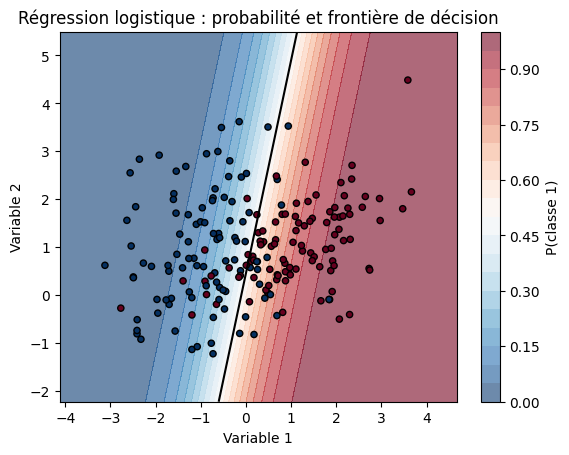

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression

X2, y2 = make_classification(n_samples=200, n_features=2, n_informative=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
m = LogisticRegression().fit(X2, y2)

xx, yy = np.meshgrid(np.linspace(X2[:,0].min()-1, X2[:,0].max()+1, 300),
                     np.linspace(X2[:,1].min()-1, X2[:,1].max()+1, 300))
proba = m.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

plt.contourf(xx, yy, proba, levels=20, cmap="RdBu_r", alpha=.6)
plt.colorbar(label="P(classe 1)")
plt.contour(xx, yy, proba, levels=[.5], colors="black")
plt.scatter(X2[:,0], X2[:,1], c=y2, cmap="RdBu_r", edgecolor="k", s=20)
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.title("Régression logistique : probabilité et frontière de décision")
plt.show()

**Comment lire ce schéma :** chaque point est une observation, coloré selon sa vraie classe. Le fond coloré indique la probabilité estimée d'appartenir à la classe 1 : rouge = probabilité élevée, bleu = probabilité faible. La ligne noire est la frontière de décision (probabilité = 0,5) : c'est une droite, car le modèle est linéaire. Les points du mauvais côté de la droite sont des erreurs de classification.

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Finance :* estimer la probabilité de défaut de paiement d'un client à partir de son historique et de ses revenus (scoring de crédit).
  2. *Marketing :* prédire si un client va répondre à une campagne ou résilier son abonnement.
- **Données et prérequis :** variables numériques standardisées (ou catégorielles encodées), cible binaire, frontière approximativement linéaire, pas de variables trop corrélées entre elles.
- **Cas peu approprié :** classes séparées par une frontière fortement non linéaire (par exemple une classe entourée par l'autre), où un modèle non linéaire est préférable.
- **Métriques :** F1, précision, rappel, ROC-AUC ou PR-AUC (surtout si les classes sont déséquilibrées) ; l'accuracy seule peut tromper.

In [10]:
from sklearn.linear_model import LogisticRegression
modele=make_pipeline(StandardScaler(),LogisticRegression(C=.2,max_iter=1500,random_state=GRAINE)).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)).fit(Xc_ent, yc_ent)
pred = logit.predict(Xc_test)
proba = logit.predict_proba(Xc_test)[:, 1]
print('F1:', f1_score(yc_test, pred))
print('Précision:', precision_score(yc_test, pred))
print('Rappel:', recall_score(yc_test, pred))
print('ROC-AUC:', roc_auc_score(yc_test, proba))
print('Accuracy:', accuracy_score(yc_test, pred))
print('Coefficients:', logit[-1].coef_)

F1: 0.8113207547169812
Précision: 0.7678571428571429
Rappel: 0.86
ROC-AUC: 0.8764
Accuracy: 0.8
Coefficients: [[ 0.76488684  0.15099154  1.14787667 -0.07091371 -0.33228504  1.29241442]]


### Analyse de l'expérience Python

- **Entrées :** Xc_ent, yc_ent (300 observations) et Xc_test, yc_test (100 observations, 50 par classe), issus de `make_classification` (6 variables dont 4 informatives, 2 classes) : données synthétiques.
- **Hyperparamètres :** C = 1.0 (par défaut), max_iter = 1000, random_state = 42, avec `StandardScaler` dans le pipeline.
- **Sortie :** F1 = 0.8113207547169812 ; précision = 0.7678571428571429 ; rappel = 0.86 ; ROC-AUC = 0.8764 ; accuracy = 0.8 ; coefficients = [0.76488684, 0.15099154, 1.14787667, -0.07091371, -0.33228504, 1.29241442].
- **Ce qu'on peut conclure :** le modèle classe correctement 80 observations sur 100. Le rappel (0.86) est plus élevé que la précision (0.77) : il détecte bien la classe 1 mais produit plus de faux positifs (13) que de faux négatifs (7). Le F1 (0.81) résume ce compromis. Un ROC-AUC de 0.876 indique que le modèle classe correctement une observation positive au-dessus d'une négative dans environ 88 % des paires. Les variables 6 (1.29), 3 (1.15) et 1 (0.76) ont les plus grands coefficients en valeur absolue, donc le plus d'influence sur la décision (variables standardisées, donc comparables). La variable 4 (-0.07) a un effet quasi nul.
- **Ce qu'on ne peut pas conclure :** un seul découpage train/test sur 100 observations : un écart de quelques points entre modèles n'est pas significatif. Les classes sont équilibrées par construction et les données sont synthétiques : le comportement sur des données réelles déséquilibrées n'est pas testé. C n'a pas été optimisé. Les coefficients ne prouvent pas de causalité et dépendent de la corrélation entre variables.

## 9. KNN

**Question ciblée (Partie B) :** Quel est l’effet d’une distance normalisée et du nombre de voisins ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** K plus proches voisins (*K-Nearest Neighbors*, KNN). Famille : **classification**. Objectif : prédire la classe d'une observation d'après les classes des observations d'entraînement les plus proches.

**Intuition :** « dis-moi qui sont tes voisins, je te dirai qui tu es ». Entrée : variables X standardisées et étiquettes y → « apprentissage » : le modèle se contente de mémoriser les données d'entraînement → sortie : pour une nouvelle observation, on trouve ses k plus proches voisins et on retient la classe majoritaire.

**Formule :** distance euclidienne d(x, x') = √( Σⱼ (xⱼ − x'ⱼ)² ) ; prédiction ŷ(x) = classe la plus fréquente parmi les k observations d'entraînement les plus proches de x.
où xⱼ et x'ⱼ sont les valeurs de la variable j pour deux observations.
- **Paramètres** : aucun coefficient appris ; le modèle est constitué des données d'entraînement elles-mêmes.
- **Hyperparamètres** (choisis) : k = `n_neighbors` (5 dans le code), la distance (euclidienne par défaut), la pondération des voisins (uniforme par défaut).

**Avantages :** (1) très simple, sans hypothèse sur la forme de la frontière (peut être non linéaire) ; (2) aucun entraînement.
**Limites :** (1) sensible à l'échelle des variables (standardisation indispensable) et aux variables inutiles ; (2) prédiction lente et mémoire élevée sur de grandes bases, car il faut comparer à toutes les observations d'entraînement.

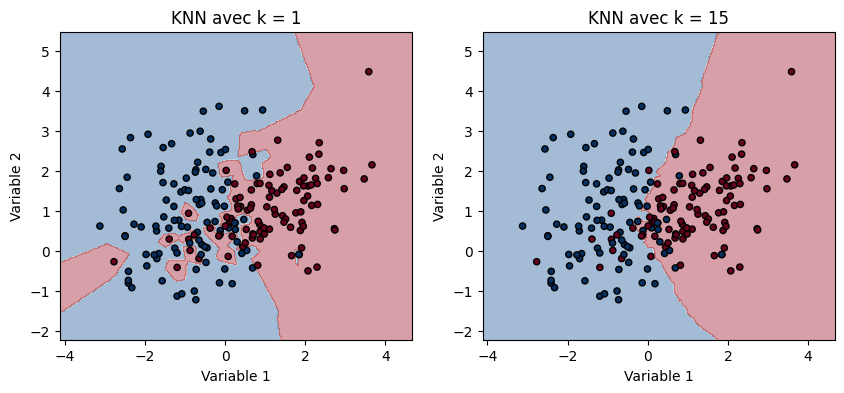

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.neighbors import KNeighborsClassifier

X2, y2 = make_classification(n_samples=200, n_features=2, n_informative=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
xx, yy = np.meshgrid(np.linspace(X2[:,0].min()-1, X2[:,0].max()+1, 300),
                     np.linspace(X2[:,1].min()-1, X2[:,1].max()+1, 300))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, k in zip(axes, [1, 15]):
    m = KNeighborsClassifier(n_neighbors=k).fit(X2, y2)
    zone = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zone, alpha=.4, cmap="RdBu_r")
    ax.scatter(X2[:,0], X2[:,1], c=y2, cmap="RdBu_r", edgecolor="k", s=20)
    ax.set_title(f"KNN avec k = {k}")
    ax.set_xlabel("Variable 1")
    ax.set_ylabel("Variable 2")
plt.show()

**Comment lire ce schéma :** chaque point est une observation, colorée selon sa vraie classe. Le fond coloré montre la classe que le modèle prédirait pour un point placé à cet endroit. À gauche (k = 1), la frontière est très découpée : chaque point isolé crée sa propre zone, ce qui traduit un surapprentissage. À droite (k = 15), la frontière est plus lisse et ignore les points isolés. Le choix de k règle donc le compromis entre sur-apprentissage (k petit) et modèle trop simple (k grand).

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Marketing / commerce :* recommander des produits ou classer un client dans un segment d'après les clients les plus similaires.
  2. *Finance :* repérer, par similarité avec des cas passés, les dossiers de crédit ressemblant à des défauts de paiement connus.
- **Données et prérequis :** variables numériques standardisées, nombre de variables modéré, base de taille raisonnable, distance pertinente pour mesurer la ressemblance.
- **Cas peu approprié :** données avec très nombreuses variables (la distance perd son sens en grande dimension), très grandes bases nécessitant des prédictions rapides, ou variables non pertinentes en grand nombre.
- **Métriques :** F1, précision, rappel, ROC-AUC ou PR-AUC.

In [11]:
from sklearn.neighbors import KNeighborsClassifier
modele=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=9,weights='distance')).fit(Xc_ent,yc_ent)
print('Exactitude:',accuracy_score(yc_test,modele.predict(Xc_test)))

Exactitude: 0.965034965034965


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xc_ent, yc_ent)
pred = knn.predict(Xc_test)
proba = knn.predict_proba(Xc_test)[:, 1]
print('F1:', f1_score(yc_test, pred))
print('Précision:', precision_score(yc_test, pred))
print('Rappel:', recall_score(yc_test, pred))
print('ROC-AUC:', roc_auc_score(yc_test, proba))
print('Accuracy:', accuracy_score(yc_test, pred))

F1: 0.8888888888888888
Précision: 0.8979591836734694
Rappel: 0.88
ROC-AUC: 0.9626
Accuracy: 0.89


### Analyse de l'expérience Python

- **Entrées :** Xc_ent, yc_ent (300 observations) et Xc_test, yc_test (100 observations, 50 par classe), issus de `make_classification` (6 variables, 2 classes) : données synthétiques.
- **Hyperparamètres :** k = 5, distance euclidienne et pondération uniforme (valeurs par défaut), avec `StandardScaler` dans le pipeline.
- **Sortie :** F1 = 0.8888888888888888 ; précision = 0.8979591836734694 ; rappel = 0.88 ; ROC-AUC = 0.9626 ; accuracy = 0.89.
- **Comparaison :** régression logistique : F1 = 0.8113, précision = 0.7679, rappel = 0.86, ROC-AUC = 0.8764, accuracy = 0.80. KNN fait mieux sur toutes les métriques : écart de F1 = 0.0776, écart de ROC-AUC = 0.0862.
- **Ce qu'on peut conclure :** KNN classe correctement 89 observations sur 100 (44 vrais positifs, 45 vrais négatifs, 5 faux positifs, 6 faux négatifs). Précision (0.90) et rappel (0.88) sont équilibrés, contrairement à la régression logistique qui produisait plus de faux positifs. KNN est meilleur que la régression logistique sur ce jeu de test. Une explication possible est que la frontière entre classes n'est pas linéaire (`make_classification` crée par défaut 2 groupes par classe), ce que KNN gère mieux ; cette hypothèse n'est pas vérifiée ici.
- **Ce qu'on ne peut pas conclure :** un seul découpage train/test sur 100 observations : un écart de 9 points est notable mais n'est pas démontré significatif. Données synthétiques, k non optimisé (on pourrait le choisir par validation croisée). Le ROC-AUC de KNN avec k = 5 repose sur seulement 6 valeurs de probabilité possibles (0, 0.2, …, 1), donc il est moins fin que celui de la régression logistique.

## 10. Naive Bayes

**Question ciblée (Partie B) :** Quelle hypothèse d’indépendance conditionnelle est faite par Naive Bayes ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** Classifieur bayésien naïf gaussien (*Gaussian Naive Bayes*). Famille : **classification**. Objectif : prédire la classe d'une observation à partir des probabilités calculées avec le théorème de Bayes.

**Intuition :** pour chaque classe, on apprend la moyenne et la variance de chaque variable. Pour une nouvelle observation, on calcule la probabilité de ses valeurs sous chaque classe, on la combine avec la fréquence de la classe, et on choisit la classe la plus probable. Entrée : X et y → apprentissage : estimation des fréquences de classes, des moyennes et des variances → sortie : probabilités par classe, puis classe la plus probable.

**Formule :** P(c | x) ∝ P(c) · Π_j N(x_j ; μ_{c,j}, σ²_{c,j})
où c est une classe, x = (x₁, …, x_p) l'observation, P(c) la fréquence de la classe c, N la densité de la loi normale, μ_{c,j} et σ²_{c,j} la moyenne et la variance de la variable j dans la classe c. Le produit suppose les variables **indépendantes** conditionnellement à la classe : c'est l'hypothèse « naïve ».
- **Paramètres** (appris) : P(c), μ_{c,j}, σ²_{c,j}.
- **Hyperparamètres** (choisis) : `var_smoothing` (petite valeur ajoutée aux variances pour la stabilité numérique, 1e-9 par défaut) ; aucun autre n'est réglé dans le code.

**Avantages :** (1) très rapide, même avec peu de données ; (2) simple à interpréter, sans réglage.
**Limites :** (1) l'hypothèse d'indépendance entre variables est rarement vraie, et des variables corrélées sont comptées plusieurs fois ; (2) les probabilités produites sont souvent mal calibrées (trop proches de 0 ou 1).

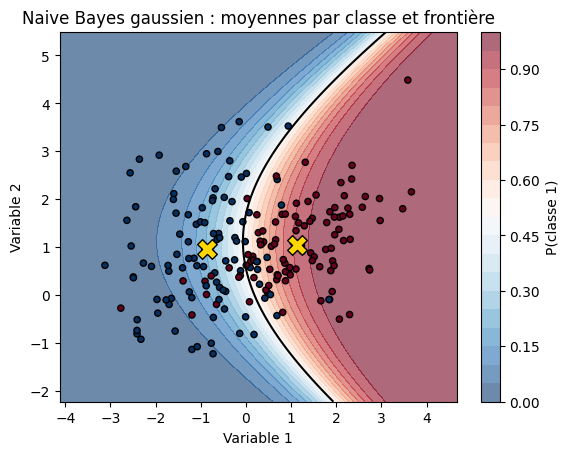

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.naive_bayes import GaussianNB

X2, y2 = make_classification(n_samples=200, n_features=2, n_informative=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
m = GaussianNB().fit(X2, y2)

xx, yy = np.meshgrid(np.linspace(X2[:,0].min()-1, X2[:,0].max()+1, 300),
                     np.linspace(X2[:,1].min()-1, X2[:,1].max()+1, 300))
proba = m.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

plt.contourf(xx, yy, proba, levels=20, cmap="RdBu_r", alpha=.6)
plt.colorbar(label="P(classe 1)")
plt.contour(xx, yy, proba, levels=[.5], colors="black")
plt.scatter(X2[:,0], X2[:,1], c=y2, cmap="RdBu_r", edgecolor="k", s=20)
for c in range(2):
    plt.scatter(*m.theta_[c], marker="X", s=200, c="gold", edgecolor="k")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.title("Naive Bayes gaussien : moyennes par classe et frontière")
plt.show()

**Comment lire ce schéma :** chaque point est une observation colorée selon sa vraie classe. Les croix jaunes marquent la moyenne de chaque classe, que le modèle estime pour chaque variable. Le fond coloré indique la probabilité d'appartenir à la classe 1 : plus on est proche du centre d'une classe et plus sa variance est adaptée, plus la probabilité de cette classe est élevée. La ligne noire est la frontière de décision (probabilité = 0,5) ; elle est courbe lorsque les variances diffèrent entre les deux classes.

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Marketing / gestion :* filtrer des courriels ou classer des avis clients par sujet ou par sentiment (version texte du Naive Bayes, avec des fréquences de mots).
  2. *Finance :* première classification rapide de transactions suspectes ou non à partir de quelques indicateurs, comme modèle de référence.
- **Données et prérequis :** variables numériques à peu près gaussiennes par classe (version gaussienne), variables peu corrélées entre elles, peu de données possibles ; pas de standardisation nécessaire.
- **Cas peu approprié :** variables fortement corrélées (l'hypothèse d'indépendance est fausse) ou quand on a besoin de probabilités fiables, par exemple pour fixer un seuil de risque.
- **Métriques :** F1, précision, rappel, ROC-AUC ou PR-AUC ; vérifier aussi la calibration si l'on utilise les probabilités.

In [12]:
from sklearn.naive_bayes import GaussianNB
modele=GaussianNB(var_smoothing=1e-8).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9621621621621622


In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, accuracy_score

nb = GaussianNB().fit(Xc_ent, yc_ent)
pred = nb.predict(Xc_test)
proba = nb.predict_proba(Xc_test)[:, 1]
print('F1:', f1_score(yc_test, pred))
print('Précision:', precision_score(yc_test, pred))
print('Rappel:', recall_score(yc_test, pred))
print('ROC-AUC:', roc_auc_score(yc_test, proba))
print('Accuracy:', accuracy_score(yc_test, pred))
print('Fréquences des classes:', nb.class_prior_)

F1: 0.7551020408163265
Précision: 0.7708333333333334
Rappel: 0.74
ROC-AUC: 0.8084
Accuracy: 0.76
Fréquences des classes: [0.49333333 0.50666667]


### Analyse de l'expérience Python

- **Entrées :** Xc_ent, yc_ent (300 observations) et Xc_test, yc_test (100 observations, 50 par classe), issus de `make_classification` (6 variables, 2 classes) : données synthétiques.
- **Hyperparamètres :** `GaussianNB()` avec ses valeurs par défaut (var_smoothing = 1e-9) ; aucune standardisation.
- **Sortie :** F1 = 0.7551020408163265 ; précision = 0.7708333333333334 ; rappel = 0.74 ; ROC-AUC = 0.8084 ; accuracy = 0.76 ; fréquences des classes = [0.49333333, 0.50666667].
- **Comparaison :** régression logistique : F1 = 0.8113, ROC-AUC = 0.8764, accuracy = 0.80. KNN : F1 = 0.8889, ROC-AUC = 0.9626, accuracy = 0.89. Naive Bayes : F1 = 0.7551, ROC-AUC = 0.8084, accuracy = 0.76. Écart de F1 = 0.0562 avec la régression logistique et 0.1338 avec KNN, en défaveur de Naive Bayes.

**Conclusion :**
- **Ce qu'on peut conclure :** Naive Bayes classe correctement 76 observations sur 100 (37 vrais positifs, 39 vrais négatifs, 11 faux positifs, 13 faux négatifs). Précision (0.77) et rappel (0.74) sont proches : le modèle n'est pas biaisé vers une classe. C'est le moins performant des trois classifieurs testés sur ce jeu de test. Les fréquences apprises (0.49 et 0.51) montrent que les classes sont quasi équilibrées dans l'entraînement.
- **Explication possible (hypothèse non vérifiée) :** Naive Bayes gaussien suppose une seule gaussienne par classe et des variables indépendantes. Or `make_classification` crée par défaut 2 groupes par classe, ce qui peut expliquer son retard sur KNN.
- **Ce qu'on ne peut pas conclure :** un seul découpage train/test sur 100 observations, donc un écart de quelques points n'est pas démontré significatif. Les données sont synthétiques et l'indépendance des variables n'a pas été vérifiée. Ses probabilités sont souvent mal calibrées, on ne doit donc pas les lire comme de vraies probabilités.

## 11. Arbre de décision

**Question ciblée (Partie B) :** Comment calculer l’impureté de Gini et choisir une séparation ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** Arbre de décision pour la classification (*Decision Tree Classifier*, type CART). Famille : **classification**. Objectif : prédire une classe en posant une suite de questions simples sur les variables.

**Intuition :** à chaque nœud, l'arbre choisit la variable et le seuil qui séparent le mieux les classes (« la variable j est-elle inférieure à s ? »). Entrée : X et y → apprentissage : découpages successifs jusqu'à la profondeur maximale → sortie : la classe majoritaire de la feuille atteinte.

**Critère :** à chaque nœud, on minimise l'impureté de Gini des deux sous-groupes :
G = 1 − Σ_c p_c²
où p_c est la proportion d'observations de la classe c dans le nœud. G vaut 0 si le nœud ne contient qu'une classe (nœud pur).
- **Paramètres** (appris) : les variables et seuils de chaque nœud, les classes des feuilles.
- **Hyperparamètres** (choisis) : `max_depth` (4 dans le code), `random_state` ; par défaut, critère de Gini.

**Avantages :** (1) très lisible : on peut tracer l'arbre et expliquer chaque décision ; (2) pas de standardisation nécessaire, capte des relations non linéaires.
**Limites :** (1) instable : un petit changement des données peut changer l'arbre ; (2) tendance au surapprentissage si la profondeur n'est pas limitée.

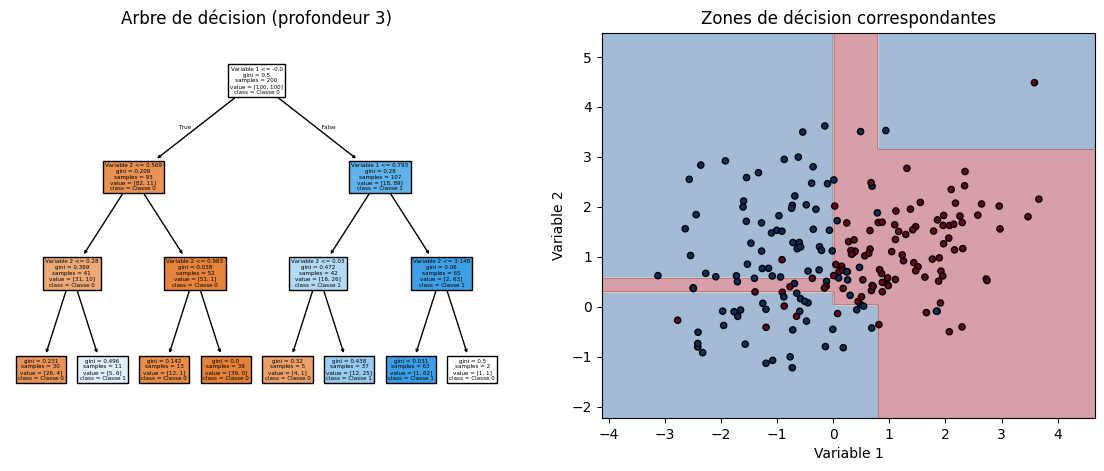

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier, plot_tree

X2, y2 = make_classification(n_samples=200, n_features=2, n_informative=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
m = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X2, y2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_tree(m, feature_names=["Variable 1", "Variable 2"], class_names=["Classe 0", "Classe 1"],
          filled=True, ax=axes[0])
axes[0].set_title("Arbre de décision (profondeur 3)")

xx, yy = np.meshgrid(np.linspace(X2[:,0].min()-1, X2[:,0].max()+1, 300),
                     np.linspace(X2[:,1].min()-1, X2[:,1].max()+1, 300))
zone = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[1].contourf(xx, yy, zone, alpha=.4, cmap="RdBu_r")
axes[1].scatter(X2[:,0], X2[:,1], c=y2, cmap="RdBu_r", edgecolor="k", s=20)
axes[1].set_xlabel("Variable 1")
axes[1].set_ylabel("Variable 2")
axes[1].set_title("Zones de décision correspondantes")
plt.show()

**Comment lire ce schéma :** à gauche, l'arbre se lit de haut en bas. Chaque rectangle non terminal indique la question posée (variable et seuil), l'impureté de Gini et le nombre d'observations ; on va à gauche si la réponse est « oui », à droite sinon. Les feuilles (en bas) donnent la classe prédite, la couleur indiquant la classe majoritaire. À droite, les mêmes décisions sont représentées dans le plan : chaque question trace une frontière horizontale ou verticale, d'où des zones rectangulaires.

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Finance / banque :* décider d'accorder ou non un crédit avec des règles lisibles par un conseiller et justifiables auprès du client.
  2. *Marketing :* segmenter les clients selon leur probabilité de réponse à une offre, avec des règles claires pour les équipes métier.
- **Données et prérequis :** variables numériques ou catégorielles encodées, pas de standardisation ; profondeur ou taille minimale des feuilles à limiter pour éviter le surapprentissage.
- **Cas peu approprié :** frontière oblique ou lisse entre les classes (l'arbre l'approxime par des marches d'escalier), ou données bruitées en petit nombre, où l'arbre est instable.
- **Métriques :** F1, précision, rappel, ROC-AUC ou PR-AUC.

In [13]:
from sklearn.tree import DecisionTreeClassifier
modele=DecisionTreeClassifier(max_depth=3,min_samples_leaf=5,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9560439560439561


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, accuracy_score

arbre_clf = DecisionTreeClassifier(max_depth=4, random_state=42).fit(Xc_ent, yc_ent)
pred = arbre_clf.predict(Xc_test)
proba = arbre_clf.predict_proba(Xc_test)[:, 1]
print('F1:', f1_score(yc_test, pred))
print('Précision:', precision_score(yc_test, pred))
print('Rappel:', recall_score(yc_test, pred))
print('ROC-AUC:', roc_auc_score(yc_test, proba))
print('Accuracy:', accuracy_score(yc_test, pred))
print('Nombre de feuilles:', arbre_clf.get_n_leaves())
print('Importance des variables:', arbre_clf.feature_importances_)

F1: 0.8910891089108911
Précision: 0.8823529411764706
Rappel: 0.9
ROC-AUC: 0.902
Accuracy: 0.89
Nombre de feuilles: 13
Importance des variables: [0.10407925 0.02278237 0.18010517 0.         0.44011371 0.25291949]


### Analyse de l'expérience Python

- **Entrées :** Xc_ent, yc_ent (300 observations) et Xc_test, yc_test (100 observations, 50 par classe), issus de `make_classification` (6 variables, 2 classes) : données synthétiques.
- **Hyperparamètres :** max_depth = 4, random_state = 42, critère de Gini par défaut ; aucune standardisation.
- **Sortie :** F1 = 0.8910891089108911 ; précision = 0.8823529411764706 ; rappel = 0.9 ; ROC-AUC = 0.902 ; accuracy = 0.89 ; nombre de feuilles = 13 ; importances = [0.10407925, 0.02278237, 0.18010517, 0.0, 0.44011371, 0.25291949].
- **Comparaison :** KNN : F1 = 0.8889, ROC-AUC = 0.9626, accuracy = 0.89. Régression logistique : F1 = 0.8113, ROC-AUC = 0.8764, accuracy = 0.80. Naive Bayes : F1 = 0.7551, ROC-AUC = 0.8084, accuracy = 0.76. Arbre : F1 = 0.8911, ROC-AUC = 0.902, accuracy = 0.89. Écart de F1 = 0.0022 avec KNN, 0.0798 avec la régression logistique, 0.1360 avec Naive Bayes.
- **Ce qu'on peut conclure :** l'arbre classe correctement 89 observations sur 100 (45 vrais positifs, 44 vrais négatifs, 6 faux positifs, 5 faux négatifs). Précision (0.88) et rappel (0.90) sont équilibrés. Il est à égalité pratique avec KNN sur le F1 et l'accuracy, et nettement meilleur que la régression logistique et Naive Bayes. Son ROC-AUC (0.902) est inférieur à celui de KNN, car l'arbre ne produit que 13 valeurs de probabilité distinctes. Les variables 5, 6, 3 et 1 portent l'essentiel de la décision ; les variables 6, 3 et 1 sont aussi celles qui dominent dans la régression logistique, et la variable 4 est négligeable dans les deux modèles.
- **Ce qu'on ne peut pas conclure :** un seul découpage train/test sur 100 observations : un écart de 0.002 de F1 n'est pas significatif, et on ne peut pas dire que l'arbre est meilleur que KNN. Données synthétiques, max_depth non optimisé. Les importances d'un arbre unique sont instables. La variable 5 est très importante pour l'arbre mais peu pour la régression logistique : l'explication par un effet non linéaire est une hypothèse non vérifiée.

## 12. Forêt aléatoire — classification

**Question ciblée (Partie B) :** Pourquoi une forêt est-elle généralement moins instable qu’un arbre seul ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** Forêt aléatoire pour la classification (*Random Forest Classifier*). Famille : **classification** (méthode d'ensemble). Objectif : prédire une classe en combinant le vote de nombreux arbres, pour réduire l'instabilité d'un arbre seul.

**Intuition :** on construit B arbres, chacun sur un échantillon tiré avec remise des données (*bootstrap*), et à chaque nœud seul un sous-ensemble aléatoire de variables est considéré. Entrée : X et y → apprentissage : entraînement indépendant des B arbres → sortie : la classe qui reçoit le plus de votes (ou, pour la probabilité, la moyenne des probabilités des arbres).

**Formule :** ŷ(x) = classe majoritaire parmi {T_1(x), …, T_B(x)} ; probabilité P(y = 1 | x) = (1/B) · Σ_b P_b(y = 1 | x)
où B est le nombre d'arbres, T_b(x) la classe prédite par le b-ième arbre et P_b la proportion de la classe 1 dans la feuille atteinte par x.
- **Paramètres** (appris) : les variables, seuils et classes de feuilles de chaque arbre.
- **Hyperparamètres** (choisis) : `n_estimators` (B = 80 dans le code), profondeur maximale, nombre de variables testées à chaque nœud, `random_state`.

**Avantages :** (1) bien plus stable et précise qu'un arbre seul grâce au vote ; (2) peu sensible au réglage, fournit des importances de variables et ne demande pas de standardisation.
**Limites :** (1) moins interprétable qu'un arbre unique ; (2) plus lente et plus gourmande en mémoire (B arbres à stocker et à interroger).

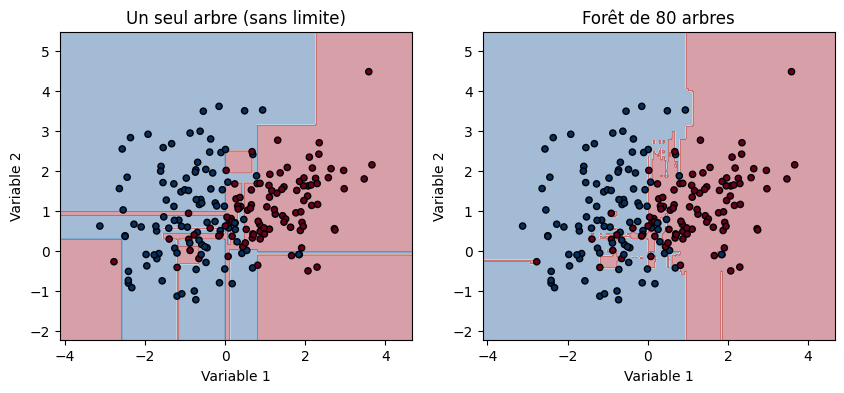

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

X2, y2 = make_classification(n_samples=200, n_features=2, n_informative=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
xx, yy = np.meshgrid(np.linspace(X2[:,0].min()-1, X2[:,0].max()+1, 300),
                     np.linspace(X2[:,1].min()-1, X2[:,1].max()+1, 300))

modeles = [("Un seul arbre (sans limite)", DecisionTreeClassifier(random_state=42)),
           ("Forêt de 80 arbres", RandomForestClassifier(n_estimators=80, random_state=42))]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nom, m) in zip(axes, modeles):
    m.fit(X2, y2)
    zone = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zone, alpha=.4, cmap="RdBu_r")
    ax.scatter(X2[:,0], X2[:,1], c=y2, cmap="RdBu_r", edgecolor="k", s=20)
    ax.set_title(nom)
    ax.set_xlabel("Variable 1")
    ax.set_ylabel("Variable 2")
plt.show()

**Comment lire ce schéma :** chaque point est une observation colorée selon sa vraie classe, et le fond coloré montre la classe prédite à cet endroit. À gauche, un arbre sans limite de profondeur isole chaque point, y compris les points atypiques : la frontière est très découpée (surapprentissage). À droite, la forêt fait voter 80 arbres entraînés sur des échantillons différents : les erreurs individuelles se compensent et la frontière est plus régulière.

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Finance :* détecter des transactions frauduleuses ou prédire le défaut de paiement à partir de nombreux indicateurs hétérogènes.
  2. *Marketing / commerce :* prédire la résiliation d'un abonnement (*churn*) à partir de l'historique d'achats et du comportement du client.
- **Données et prérequis :** données tabulaires numériques ou catégorielles encodées, relations non linéaires et interactions ; pas de standardisation ; assez d'observations.
- **Cas peu approprié :** besoin d'un modèle entièrement explicable (règles à justifier une par une), prédictions en temps réel sur du matériel très limité, ou données non tabulaires (images, texte brut) où d'autres modèles sont plus adaptés.
- **Métriques :** F1, précision, rappel, ROC-AUC ou PR-AUC (surtout si les classes sont déséquilibrées).

In [14]:
from sklearn.ensemble import RandomForestClassifier
modele=RandomForestClassifier(n_estimators=110,max_depth=6,random_state=GRAINE,n_jobs=-1).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9613259668508287


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, accuracy_score

foret_clf = RandomForestClassifier(n_estimators=80, random_state=42).fit(Xc_ent, yc_ent)
pred = foret_clf.predict(Xc_test)
proba = foret_clf.predict_proba(Xc_test)[:, 1]
print('F1:', f1_score(yc_test, pred))
print('Précision:', precision_score(yc_test, pred))
print('Rappel:', recall_score(yc_test, pred))
print('ROC-AUC:', roc_auc_score(yc_test, proba))
print('Accuracy:', accuracy_score(yc_test, pred))
print('Importance des variables:', foret_clf.feature_importances_)

F1: 0.9183673469387755
Précision: 0.9375
Rappel: 0.9
ROC-AUC: 0.9822
Accuracy: 0.92
Importance des variables: [0.16425579 0.08056732 0.19150929 0.07445267 0.23401316 0.25520177]


### Analyse de l'expérience Python

- **Entrées :** Xc_ent, yc_ent (300 observations) et Xc_test, yc_test (100 observations, 50 par classe), issus de `make_classification` (6 variables, 2 classes) : données synthétiques.
- **Hyperparamètres :** n_estimators = 80, random_state = 42, autres valeurs par défaut ; aucune standardisation.
- **Sortie :** F1 = 0.9183673469387755 ; précision = 0.9375 ; rappel = 0.9 ; ROC-AUC = 0.9822 ; accuracy = 0.92 ; importances = [0.16425579, 0.08056732, 0.19150929, 0.07445267, 0.23401316, 0.25520177].
- **Comparaison :** arbre (max_depth=4) : F1 = 0.8911, ROC-AUC = 0.902, accuracy = 0.89. KNN : F1 = 0.8889, ROC-AUC = 0.9626, accuracy = 0.89. Régression logistique : F1 = 0.8113, ROC-AUC = 0.8764, accuracy = 0.80. Naive Bayes : F1 = 0.7551, ROC-AUC = 0.8084, accuracy = 0.76. Forêt : F1 = 0.9184, ROC-AUC = 0.9822, accuracy = 0.92. Écart de F1 = 0.0273 avec l'arbre, 0.0295 avec KNN, 0.1071 avec la régression logistique, 0.1633 avec Naive Bayes.
- **Ce qu'on peut conclure :** la forêt classe correctement 92 observations sur 100 (45 vrais positifs, 47 vrais négatifs, 3 faux positifs, 5 faux négatifs). Elle obtient les meilleures valeurs de F1, de ROC-AUC et d'accuracy parmi les cinq classifieurs testés. Son ROC-AUC (0.982) est nettement supérieur à celui de l'arbre seul (0.902), ce qui est cohérent avec le fait qu'elle moyenne les probabilités de 80 arbres et classe donc les observations plus finement. Les variables 6, 5, 3 et 1 portent l'essentiel de la décision, comme pour l'arbre, mais l'importance est mieux répartie entre les variables.
- **Ce qu'on ne peut pas conclure :** un seul découpage train/test sur 100 observations : un écart de F1 de 0.03 (2 à 3 observations) n'est pas démontré significatif. Données synthétiques, hyperparamètres non optimisés. Les importances de scikit-learn peuvent être biaisées en faveur des variables à nombreuses valeurs distinctes.

## 13. SVM

**Question ciblée (Partie B) :** À quoi servent les vecteurs de support et le paramètre C ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** Machine à vecteurs de support (*Support Vector Machine*, SVM ; ici `SVC` avec noyau RBF). Famille : **classification**. Objectif : trouver la frontière qui sépare les classes avec la plus grande marge possible.

**Intuition :** parmi toutes les frontières possibles, le SVM choisit celle qui est la plus éloignée des observations les plus proches de chaque classe (les **vecteurs de support**). Avec un noyau, il peut tracer des frontières courbes. Entrée : variables X standardisées et étiquettes y → apprentissage : résolution d'un problème d'optimisation qui détermine les vecteurs de support → sortie : un score de décision, dont le signe donne la classe.

**Formule :** f(x) = Σᵢ αᵢ yᵢ K(xᵢ, x) + b, avec le noyau RBF K(x, x') = exp(−γ ‖x − x'‖²)
où xᵢ sont les vecteurs de support, yᵢ leurs classes (−1 ou +1), αᵢ leurs poids appris, b le biais, et γ la portée du noyau. On minimise ½‖w‖² + C Σ ξᵢ, où ξᵢ mesure de combien une observation viole la marge.
- **Paramètres** (appris) : les poids αᵢ (donc les vecteurs de support) et b.
- **Hyperparamètres** (choisis) : le noyau (`rbf`), `C` (1.0 dans le code : tolérance aux erreurs de marge), `gamma` (valeur par défaut `'scale'`).

**Avantages :** (1) efficace en grande dimension et capable de frontières non linéaires grâce aux noyaux ; (2) la marge maximale donne souvent une bonne généralisation.
**Limites :** (1) sensible à l'échelle des variables et au choix de C et gamma ; (2) lent sur de très grandes bases, et ne fournit pas directement de probabilités.

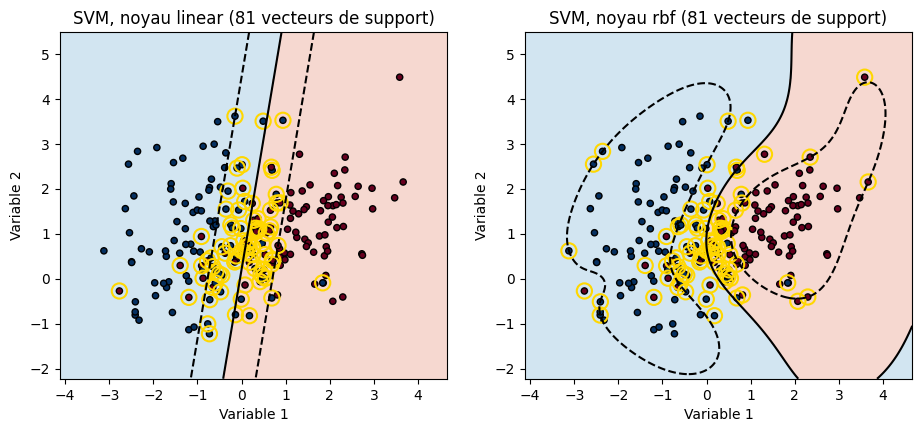

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.svm import SVC

X2, y2 = make_classification(n_samples=200, n_features=2, n_informative=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
xx, yy = np.meshgrid(np.linspace(X2[:,0].min()-1, X2[:,0].max()+1, 300),
                     np.linspace(X2[:,1].min()-1, X2[:,1].max()+1, 300))
grille = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, noyau in zip(axes, ["linear", "rbf"]):
    m = SVC(kernel=noyau, C=1.0).fit(X2, y2)
    score = m.decision_function(grille).reshape(xx.shape)
    ax.contourf(xx, yy, score > 0, alpha=.3, cmap="RdBu_r")
    ax.contour(xx, yy, score, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    ax.scatter(X2[:,0], X2[:,1], c=y2, cmap="RdBu_r", edgecolor="k", s=20)
    ax.scatter(m.support_vectors_[:,0], m.support_vectors_[:,1], s=120, facecolors="none", edgecolors="gold", linewidths=1.5)
    ax.set_title(f"SVM, noyau {noyau} ({len(m.support_vectors_)} vecteurs de support)")
    ax.set_xlabel("Variable 1")
    ax.set_ylabel("Variable 2")
plt.show()

**Comment lire ce schéma :** chaque point est une observation colorée selon sa vraie classe ; le fond indique la classe prédite. La ligne noire pleine est la frontière de décision (score = 0) et les lignes pointillées sont les bords de la marge (score = ±1). Les points entourés en jaune sont les vecteurs de support : ce sont les seuls qui déterminent la frontière. À gauche, avec un noyau linéaire, la frontière est une droite. À droite, avec le noyau RBF, elle peut se courber pour suivre la forme des classes.

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Finance :* classer des dossiers (défaut ou non, transaction suspecte ou non) à partir de nombreux indicateurs, sur des bases de taille moyenne.
  2. *Marketing :* classer des avis clients ou des textes selon leur sentiment (représentations en grande dimension, où le SVM linéaire est classique).
- **Données et prérequis :** variables numériques standardisées, base de taille petite à moyenne (quelques milliers à dizaines de milliers de lignes), réglage de C et gamma par validation croisée.
- **Cas peu approprié :** très grandes bases (temps d'entraînement qui croît fortement avec le nombre d'observations), ou cas où l'on a besoin de probabilités calibrées et d'un modèle facilement explicable.
- **Métriques :** F1, précision, rappel, ROC-AUC ou PR-AUC (à partir du score de décision).

In [15]:
from sklearn.svm import SVC
modele=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=2.,gamma='scale')).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

svm = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0, random_state=42)).fit(Xc_ent, yc_ent)
pred = svm.predict(Xc_test)
score = svm.decision_function(Xc_test)
print('F1:', f1_score(yc_test, pred))
print('Précision:', precision_score(yc_test, pred))
print('Rappel:', recall_score(yc_test, pred))
print('ROC-AUC (score de décision):', roc_auc_score(yc_test, score))
print('Accuracy:', accuracy_score(yc_test, pred))
print('Vecteurs de support par classe:', svm[-1].n_support_)

F1: 0.8979591836734694
Précision: 0.9166666666666666
Rappel: 0.88
ROC-AUC (score de décision): 0.9736
Accuracy: 0.9
Vecteurs de support par classe: [86 91]


### Analyse de l'expérience Python

- **Entrées :** Xc_ent, yc_ent (300 observations) et Xc_test, yc_test (100 observations, 50 par classe), issus de `make_classification` (6 variables, 2 classes) : données synthétiques.
- **Hyperparamètres :** noyau RBF, C = 1.0, gamma = 'scale' (par défaut), avec `StandardScaler` dans le pipeline. Le `random_state` n'a pas d'effet ici (il ne sert que si l'on active les probabilités).
- **Sortie :** F1 = 0.8979591836734694 ; précision = 0.9166666666666666 ; rappel = 0.88 ; ROC-AUC (score de décision) = 0.9736 ; accuracy = 0.9 ; vecteurs de support par classe = [86, 91].
- **Comparaison :** forêt : F1 = 0.9184, ROC-AUC = 0.9822, accuracy = 0.92. Arbre : F1 = 0.8911, ROC-AUC = 0.902, accuracy = 0.89. KNN : F1 = 0.8889, ROC-AUC = 0.9626, accuracy = 0.89. Régression logistique : F1 = 0.8113, ROC-AUC = 0.8764, accuracy = 0.80. Naive Bayes : F1 = 0.7551, ROC-AUC = 0.8084, accuracy = 0.76. SVM : F1 = 0.8980, ROC-AUC = 0.9736, accuracy = 0.90. Écart de F1 = 0.0204 avec la forêt, 0.0091 avec KNN, 0.0069 avec l'arbre, 0.0867 avec la régression logistique, 0.1429 avec Naive Bayes.
- **Ce qu'on peut conclure :** le SVM classe correctement 90 observations sur 100 (44 vrais positifs, 46 vrais négatifs, 4 faux positifs, 6 faux négatifs). Précision (0.92) et rappel (0.88) sont proches. Il se classe deuxième derrière la forêt sur le F1, le ROC-AUC et l'accuracy, et nettement devant la régression logistique et Naive Bayes. Le modèle retient 177 vecteurs de support sur 300 observations (environ 59 %) : une grande partie des données définit la frontière, ce qui indique que les deux classes se chevauchent.
- **Ce qu'on ne peut pas conclure :** un seul découpage train/test sur 100 observations : les écarts avec la forêt, l'arbre et KNN (1 à 2 observations) ne sont pas démontrés significatifs. Données synthétiques, C et gamma non optimisés. Le ROC-AUC est calculé à partir du score de décision, pas d'une probabilité calibrée.

## 14. Gradient Boosting — classification

**Question ciblée (Partie B) :** Comment corriger progressivement les erreurs de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** Gradient Boosting pour la classification (*Gradient Boosting Classifier*, ici `HistGradientBoostingClassifier` de scikit-learn). Famille : **classification** (méthode d'ensemble). Objectif : prédire une classe en additionnant de petits arbres, chacun corrigeant les erreurs des précédents.

**Intuition :** on part d'un score initial (le log-odds de la classe majoritaire), puis on ajoute, étape par étape, un petit arbre entraîné à corriger les erreurs restantes (le gradient de la perte logistique). Entrée : X et y → apprentissage : ajouts successifs d'arbres, chacun multiplié par un petit pas → sortie : un score cumulé, transformé en probabilité par la fonction sigmoïde, puis en classe.

**Formule :** F_m(x) = F_{m−1}(x) + η · h_m(x) ; P(y = 1 | x) = 1 / (1 + e^{−F_M(x)})
où F_m est le score après m étapes, h_m le m-ième petit arbre ajusté sur le gradient négatif de la perte logistique, η le taux d'apprentissage (*learning rate*) et M le nombre d'arbres.
- **Paramètres** (appris) : la structure et les valeurs des feuilles de chaque arbre h_m.
- **Hyperparamètres** (choisis) : `max_iter` (M = 80 dans le code), taux d'apprentissage η (valeur par défaut), profondeur / nombre de feuilles, `random_state`.

**Avantages :** (1) très précis sur des données tabulaires, avec interactions et non-linéarités ; (2) accepte les valeurs manquantes et reste rapide (version Hist).
**Limites :** (1) sensible au réglage des hyperparamètres et au surapprentissage si trop d'itérations ; (2) entraînement séquentiel et moins interprétable qu'un arbre seul.

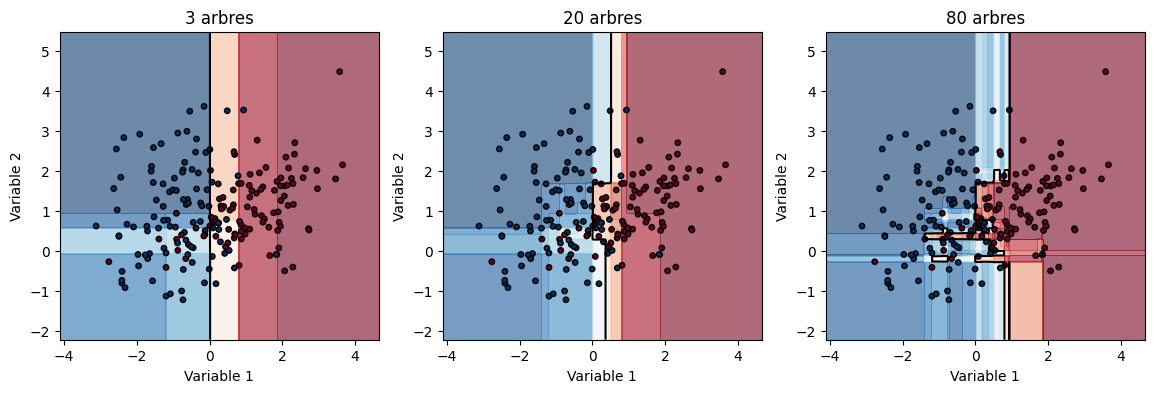

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.ensemble import HistGradientBoostingClassifier

X2, y2 = make_classification(n_samples=200, n_features=2, n_informative=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
xx, yy = np.meshgrid(np.linspace(X2[:,0].min()-1, X2[:,0].max()+1, 300),
                     np.linspace(X2[:,1].min()-1, X2[:,1].max()+1, 300))
grille = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, n in zip(axes, [3, 20, 80]):
    m = HistGradientBoostingClassifier(max_iter=n, random_state=42).fit(X2, y2)
    proba = m.predict_proba(grille)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, proba, levels=20, cmap="RdBu_r", alpha=.6)
    ax.contour(xx, yy, proba, levels=[.5], colors="k")
    ax.scatter(X2[:,0], X2[:,1], c=y2, cmap="RdBu_r", edgecolor="k", s=15)
    ax.set_title(f"{n} arbres")
    ax.set_xlabel("Variable 1")
    ax.set_ylabel("Variable 2")
plt.show()

**Comment lire ce schéma :** chaque point est une observation colorée selon sa vraie classe ; le fond indique la probabilité estimée d'appartenir à la classe 1 (rouge = élevée, bleu = faible) et la ligne noire est la frontière de décision (probabilité = 0,5). Avec 3 arbres, le modèle est encore grossier et la frontière simple. Avec 20 puis 80 arbres, la frontière se précise et suit mieux les données : chaque arbre ajouté corrige une partie des erreurs restantes. C'est le principe du boosting.

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Finance :* scoring de crédit ou détection de fraude à partir de nombreux indicateurs hétérogènes.
  2. *Marketing / commerce :* prédire la résiliation (*churn*) ou la réponse à une offre à partir de l'historique client.
- **Données et prérequis :** données tabulaires, relations non linéaires et interactions ; pas de standardisation ; réglage des hyperparamètres par validation croisée ; assez d'observations.
- **Cas peu approprié :** très peu de données (surapprentissage), besoin d'un modèle entièrement explicable, ou données non tabulaires (images, texte brut).
- **Métriques :** F1, précision, rappel, ROC-AUC ou PR-AUC (surtout si les classes sont déséquilibrées).

In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier
modele=HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=10,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, accuracy_score

gb_clf = HistGradientBoostingClassifier(max_iter=80, random_state=42).fit(Xc_ent, yc_ent)
pred = gb_clf.predict(Xc_test)
proba = gb_clf.predict_proba(Xc_test)[:, 1]
print('F1:', f1_score(yc_test, pred))
print('Précision:', precision_score(yc_test, pred))
print('Rappel:', recall_score(yc_test, pred))
print('ROC-AUC:', roc_auc_score(yc_test, proba))
print('Accuracy:', accuracy_score(yc_test, pred))

F1: 0.96
Précision: 0.96
Rappel: 0.96
ROC-AUC: 0.9884
Accuracy: 0.96


### Analyse de l'expérience Python

- **Entrées :** Xc_ent, yc_ent (300 observations) et Xc_test, yc_test (100 observations, 50 par classe), issus de `make_classification` (6 variables, 2 classes) : données synthétiques.
- **Hyperparamètres :** max_iter = 80, random_state = 42, autres valeurs par défaut (dont le taux d'apprentissage) ; aucune standardisation.
- **Sortie :** F1 = 0.96 ; précision = 0.96 ; rappel = 0.96 ; ROC-AUC = 0.9884 ; accuracy = 0.96.
- **Comparaison :** forêt : F1 = 0.9184, ROC-AUC = 0.9822, accuracy = 0.92. SVM : F1 = 0.8980, ROC-AUC = 0.9736, accuracy = 0.90. Arbre : F1 = 0.8911, ROC-AUC = 0.902, accuracy = 0.89. KNN : F1 = 0.8889, ROC-AUC = 0.9626, accuracy = 0.89. Régression logistique : F1 = 0.8113, ROC-AUC = 0.8764, accuracy = 0.80. Naive Bayes : F1 = 0.7551, ROC-AUC = 0.8084, accuracy = 0.76. Boosting : F1 = 0.96, ROC-AUC = 0.9884, accuracy = 0.96. Écart de F1 = 0.0416 avec la forêt, 0.0620 avec le SVM, 0.0689 avec l'arbre, 0.0711 avec KNN, 0.1487 avec la régression logistique, 0.2049 avec Naive Bayes.
- **Ce qu'on peut conclure :** le boosting classe correctement 96 observations sur 100 (48 vrais positifs, 48 vrais négatifs, 2 faux positifs, 2 faux négatifs). Précision et rappel sont parfaitement équilibrés (0.96). Il obtient les meilleures valeurs de F1, de ROC-AUC et d'accuracy parmi les six classifieurs testés sur ce jeu de test.
- **Ce qu'on ne peut pas conclure :** un seul découpage train/test sur 100 observations : l'écart de 4 observations avec la forêt n'est pas démontré significatif, un autre découpage pourrait changer le classement. Données synthétiques, hyperparamètres non optimisés (nombre d'itérations, taux d'apprentissage). On ne peut pas en déduire que le boosting est toujours supérieur : sur d'autres données, le classement peut différer.

## 15. AdaBoost

**Question ciblée (Partie B) :** Comment AdaBoost repondère-t-il les exemples difficiles ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

**Nom :** AdaBoost (*Adaptive Boosting*). Famille : **classification** (méthode d'ensemble). Objectif : construire un classifieur fort en combinant de nombreux classifieurs faibles (par défaut, des arbres de profondeur 1 appelés « souches »).

**Intuition :** on entraîne une première souche, puis on augmente le poids des observations qu'elle a mal classées, et on entraîne la souche suivante sur ces poids. Chaque souche reçoit un poids de vote d'autant plus grand qu'elle est précise. Entrée : X et y → apprentissage : séquence de souches sur des observations repondérées → sortie : vote pondéré de toutes les souches.

**Formule :** H(x) = signe( Σₘ αₘ hₘ(x) ), avec αₘ = ½ ln((1 − εₘ) / εₘ)
où hₘ(x) ∈ {−1, +1} est la prédiction de la m-ième souche, εₘ son erreur pondérée et αₘ son poids de vote. (Scikit-learn utilise la variante multi-classes SAMME, équivalente en binaire.)
- **Paramètres** (appris) : les souches hₘ et leurs poids αₘ.
- **Hyperparamètres** (choisis) : `n_estimators` (70 dans le code), taux d'apprentissage, classifieur de base, `random_state`.

**Avantages :** (1) simple et efficace, avec peu de réglages ; (2) se concentre automatiquement sur les cas difficiles.
**Limites :** (1) sensible au bruit et aux valeurs aberrantes (il leur donne de plus en plus de poids) ; (2) entraînement séquentiel, donc non parallélisable.

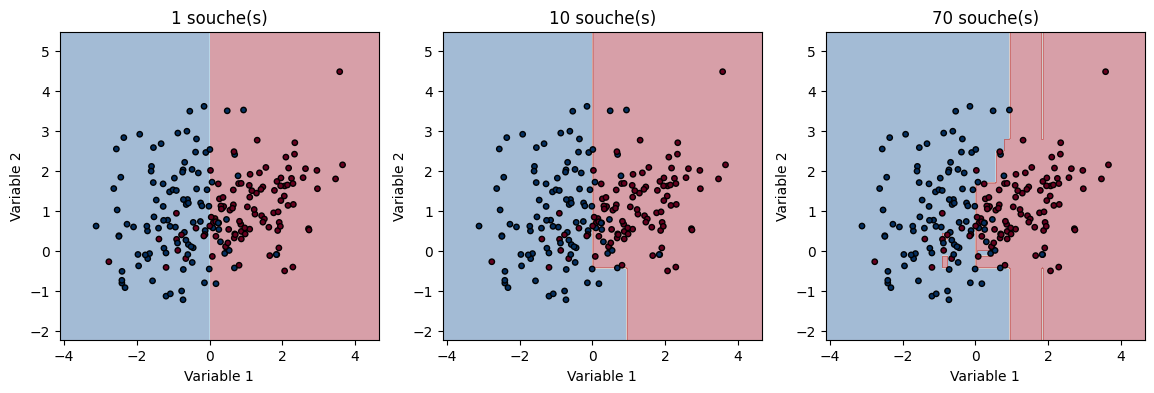

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.ensemble import AdaBoostClassifier

X2, y2 = make_classification(n_samples=200, n_features=2, n_informative=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
xx, yy = np.meshgrid(np.linspace(X2[:,0].min()-1, X2[:,0].max()+1, 300),
                     np.linspace(X2[:,1].min()-1, X2[:,1].max()+1, 300))
grille = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, n in zip(axes, [1, 10, 70]):
    m = AdaBoostClassifier(n_estimators=n, random_state=42).fit(X2, y2)
    zone = m.predict(grille).reshape(xx.shape)
    ax.contourf(xx, yy, zone, alpha=.4, cmap="RdBu_r")
    ax.scatter(X2[:,0], X2[:,1], c=y2, cmap="RdBu_r", edgecolor="k", s=15)
    ax.set_title(f"{n} souche(s)")
    ax.set_xlabel("Variable 1")
    ax.set_ylabel("Variable 2")
plt.show()

**Comment lire ce schéma :** chaque point est une observation colorée selon sa vraie classe ; le fond indique la classe prédite. Avec 1 souche, la frontière est une seule coupure horizontale ou verticale : le modèle est très simple. Avec 10 puis 70 souches, les coupures se combinent en une frontière en escalier de plus en plus fine, car chaque nouvelle souche se concentre sur les points mal classés par les précédentes.

### Contextes d'utilisation

- **Deux cas d'usage :**
  1. *Finance :* première détection de transactions suspectes à partir de quelques indicateurs, avec un modèle rapide à entraîner.
  2. *Marketing :* prédire si un client répondra à une offre à partir de variables simples, en combinant de nombreuses règles élémentaires.
- **Données et prérequis :** données tabulaires, données peu bruitées, classifieurs faibles simples ; pas de standardisation nécessaire.
- **Cas peu approprié :** données contenant beaucoup d'étiquettes erronées ou de valeurs aberrantes, car AdaBoost leur accorde un poids croissant.
- **Métriques :** F1, précision, rappel, ROC-AUC ou PR-AUC.

In [17]:
from sklearn.ensemble import AdaBoostClassifier
modele=AdaBoostClassifier(n_estimators=90,learning_rate=.7,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, accuracy_score

ada = AdaBoostClassifier(n_estimators=70, random_state=42).fit(Xc_ent, yc_ent)
pred = ada.predict(Xc_test)
proba = ada.predict_proba(Xc_test)[:, 1]
print('F1:', f1_score(yc_test, pred))
print('Précision:', precision_score(yc_test, pred))
print('Rappel:', recall_score(yc_test, pred))
print('ROC-AUC:', roc_auc_score(yc_test, proba))
print('Accuracy:', accuracy_score(yc_test, pred))
print('Importance des variables:', ada.feature_importances_)

F1: 0.8269230769230769
Précision: 0.7962962962962963
Rappel: 0.86
ROC-AUC: 0.9198000000000001
Accuracy: 0.82
Importance des variables: [0.23130599 0.         0.17232146 0.         0.41392787 0.18244469]


### Analyse de l'expérience Python

- **Entrées :** Xc_ent, yc_ent (300 observations) et Xc_test, yc_test (100 observations, 50 par classe), issus de `make_classification` (6 variables, 2 classes) : données synthétiques.
- **Hyperparamètres :** n_estimators = 70, random_state = 42, autres valeurs par défaut (souches de profondeur 1, taux d'apprentissage 1.0) ; aucune standardisation.
- **Sortie :** F1 = 0.8269230769230769 ; précision = 0.7962962962962963 ; rappel = 0.86 ; ROC-AUC = 0.9198 ; accuracy = 0.82 ; importances = [0.23130599, 0.0, 0.17232146, 0.0, 0.41392787, 0.18244469].
- **Comparaison :** gradient boosting : F1 = 0.96, ROC-AUC = 0.9884, accuracy = 0.96. Forêt : F1 = 0.9184, ROC-AUC = 0.9822, accuracy = 0.92. SVM : F1 = 0.8980, ROC-AUC = 0.9736, accuracy = 0.90. Arbre : F1 = 0.8911, ROC-AUC = 0.902, accuracy = 0.89. KNN : F1 = 0.8889, ROC-AUC = 0.9626, accuracy = 0.89. Régression logistique : F1 = 0.8113, ROC-AUC = 0.8764, accuracy = 0.80. Naive Bayes : F1 = 0.7551, ROC-AUC = 0.8084, accuracy = 0.76. AdaBoost : F1 = 0.8269, ROC-AUC = 0.9198, accuracy = 0.82. Écart de F1 = 0.1331 avec le gradient boosting, 0.0915 avec la forêt, 0.0711 avec le SVM, 0.0642 avec l'arbre, 0.0620 avec KNN (en défaveur d'AdaBoost) ; 0.0156 avec la régression logistique et 0.0718 avec Naive Bayes (en faveur d'AdaBoost).
- **Ce qu'on peut conclure :** AdaBoost classe correctement 82 observations sur 100 (43 vrais positifs, 39 vrais négatifs, 11 faux positifs, 7 faux négatifs). Le rappel (0.86) est supérieur à la précision (0.80) : le modèle prédit un peu trop de « 1 ». Sur ce jeu de test, il est nettement moins performant que le gradient boosting, la forêt, le SVM, l'arbre et KNN, et proche de la régression logistique. Les variables 5, 1, 6 et 3 portent la décision ; les variables 2 et 4 ne sont jamais utilisées, ce qui concorde avec l'arbre de décision.
- **Ce qu'on ne peut pas conclure :** un seul découpage train/test sur 100 observations : un écart de quelques points n'est pas démontré significatif (l'écart avec la régression logistique, 1,6 point, ne l'est certainement pas). Données synthétiques, hyperparamètres non optimisés (nombre de souches, taux d'apprentissage, profondeur de base). L'explication par la profondeur 1 des souches, qui empêcherait de capter les interactions, est une hypothèse non vérifiée. Les probabilités d'AdaBoost sont peu calibrées.

## 16. XGBoost

**Question ciblée (Partie B) :** Quel est le rôle de la régularisation et du learning_rate dans XGBoost ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [18]:
from xgboost import XGBClassifier
modele=XGBClassifier(n_estimators=100,max_depth=2,learning_rate=.09,random_state=GRAINE,eval_metric='logloss').fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.978021978021978


## 17. K-means

**Question ciblée (Partie B) :** Comment affecter chaque vin à son centroïde puis recalculer celui-ci ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

Silhouette: 0.5610505693103246


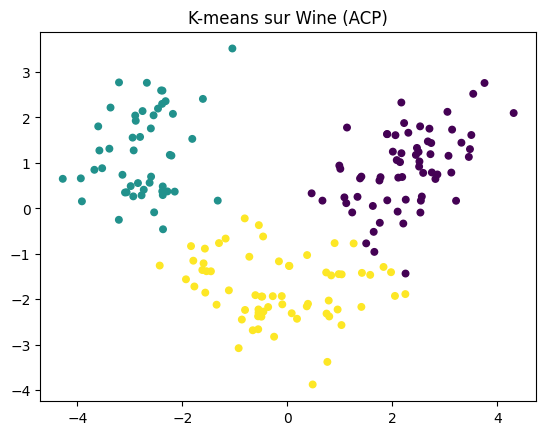

In [19]:
from sklearn.cluster import KMeans
modele=KMeans(n_clusters=3,n_init=15,random_state=GRAINE).fit(X_clu)
print('Silhouette:',silhouette_score(X_clu,modele.labels_))
plt.scatter(X_clu[:,0],X_clu[:,1],c=modele.labels_,s=22);plt.title('K-means sur Wine (ACP)');plt.show()

## 18. Classification hiérarchique

**Question ciblée (Partie B) :** Que montre un dendrogramme et comment définit-on le lien de Ward ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [20]:
from sklearn.cluster import AgglomerativeClustering
etiquettes=AgglomerativeClustering(n_clusters=3,linkage='ward').fit_predict(X_clu)
print('Silhouette:',silhouette_score(X_clu,etiquettes))

Silhouette: 0.5590883962040383


## 19. DBSCAN

**Question ciblée (Partie B) :** À quoi correspondent les points marqués comme bruit par DBSCAN ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [21]:
from sklearn.cluster import DBSCAN
etiquettes=DBSCAN(eps=.7,min_samples=6).fit_predict(X_clu)
print('Groupes:',len(set(etiquettes)-{-1}),'Bruit:',int((etiquettes==-1).sum()))

Groupes: 2 Bruit: 8


## 20. Mélanges gaussiens

**Question ciblée (Partie B) :** En quoi les appartenances probabilistes diffèrent-elles d’une affectation dure ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [22]:
from sklearn.mixture import GaussianMixture
modele=GaussianMixture(n_components=3,covariance_type='full',random_state=GRAINE).fit(X_clu)
etiquettes=modele.predict(X_clu)
print('Poids des groupes:',modele.weights_.round(3),'Silhouette:',silhouette_score(X_clu,etiquettes))

Poids des groupes: [0.38  0.269 0.351] Silhouette: 0.5591116207103001


## 21. ACP

**Question ciblée (Partie B) :** Que mesure la variance expliquée par les deux axes de l’ACP ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

Variance expliquée: [0.12  0.096]


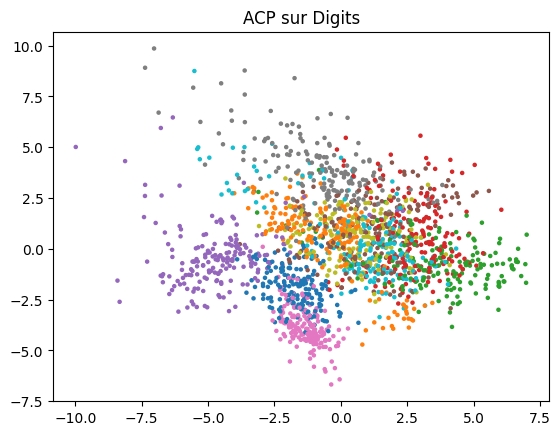

In [23]:
from sklearn.decomposition import PCA
modele=PCA(n_components=2,random_state=GRAINE).fit(X_images)
projection=modele.transform(X_images)
print('Variance expliquée:',modele.explained_variance_ratio_.round(3))
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target,cmap='tab10',s=5);plt.title('ACP sur Digits');plt.show()

## 22. t-SNE

**Question ciblée (Partie B) :** Pourquoi la distance entre groupes éloignés peut-elle être trompeuse en t-SNE ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

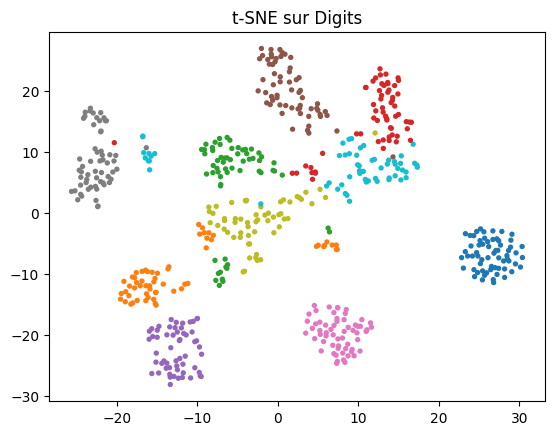

In [24]:
from sklearn.manifold import TSNE
projection=TSNE(n_components=2,perplexity=35,random_state=GRAINE,init='pca').fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('t-SNE sur Digits');plt.show()

## 23. UMAP

**Question ciblée (Partie B) :** Quel est l’effet de n_neighbors et min_dist sur les voisinages ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


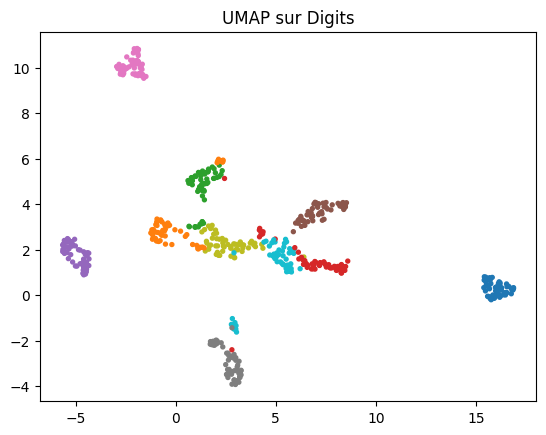

In [25]:
import umap
projection=umap.UMAP(n_components=2,n_neighbors=20,min_dist=.15,random_state=GRAINE).fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('UMAP sur Digits');plt.show()

## 24. Isolation Forest

**Question ciblée (Partie B) :** Pourquoi une observation statistiquement atypique n’est-elle pas forcément une erreur ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [26]:
from sklearn.ensemble import IsolationForest
# Recherche d'observations atypiques dans les caractéristiques de vins (sans ajouter de faux points)
modele=IsolationForest(contamination=.05,n_estimators=150,random_state=GRAINE).fit(X_clu)
indices=np.where(modele.predict(X_clu)==-1)[0]
print('Nombre de vins atypiques:',len(indices),'Indices (extrait):',indices[:12])

Nombre de vins atypiques: 9 Indices (extrait): [  3  14  18  59  80 115 146 158 177]


## 25. Bandits manchots

**Question ciblée (Partie B) :** Comment calculer une estimation du gain moyen de chaque bras ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [27]:
# Bandit simulé à 4 choix : la politique choisit successivement chaque bras
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int)
for t in range(800):
    bras=t%4
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Probabilités estimées:',(sommes/comptes).round(3))

Probabilités estimées: [0.205 0.335 0.605 0.765]


## 26. Epsilon-greedy

**Question ciblée (Partie B) :** Quelle différence entre exploration aléatoire et exploitation du meilleur bras estimé ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [28]:
# Epsilon-greedy sur les mêmes 4 bras simulés
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int);epsilon=.15
for t in range(1200):
    bras=int(generateur.integers(4)) if generateur.random()<epsilon else int(np.argmax((sommes+1)/(comptes+2)))
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Nombre de choix:',comptes,'Estimations:',(sommes/np.maximum(comptes,1)).round(3))

Nombre de choix: [  55   53   44 1048] Estimations: [0.182 0.377 0.614 0.751]


## 27. Q-learning

**Question ciblée (Partie B) :** Comment calculer une cible de Bellman dans Taxi et pourquoi le max intervient-il ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [29]:
# Q-learning manuel sur Taxi-v3 : exploration epsilon-greedy
import gymnasium as gym
env=gym.make('Taxi-v3');Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400)
    for pas in range(200):
        action=int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
        suivant,recompense,termine,tronque,_=env.step(action)
        cible=recompense+(0 if termine else .96*np.max(Q[suivant]))
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat=suivant
        if termine or tronque:break
print('Q-learning Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2));env.close()

/usr/local/lib/python3.13/dist-packages/gymnasium/envs/registration.py:511: DeprecationWarning: WARN: The environment Taxi-v3 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


DeprecatedEnv: Environment version v3 for `Taxi` is deprecated. Please use `Taxi-v4` instead.

## 28. SARSA

**Question ciblée (Partie B) :** Pourquoi SARSA met-il à jour Q avec l’action suivante réellement choisie ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# SARSA manuel sur Taxi-v3 (on-policy)
import gymnasium as gym
env=gym.make('Taxi-v3');Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
def choisir_action(etat,epsilon):
    return int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400);action=choisir_action(etat,epsilon)
    for pas in range(200):
        suivant,recompense,termine,tronque,_=env.step(action)
        action_suiv=choisir_action(suivant,epsilon)
        cible=recompense+(0 if termine else .96*Q[suivant,action_suiv])
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat,action=suivant,action_suiv
        if termine or tronque:break
print('SARSA Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2));env.close()

## 29. DQN — cible conceptuelle

**Question ciblée (Partie B) :** Pourquoi un DQN complet a-t-il besoin d’un réseau cible et d’une mémoire de rejouement ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# DQN : calcul pédagogique d'une cible de Bellman (aucun réseau entraîné)
recompenses=np.array([2.,-1.,10.,0.]);termine=np.array([False,False,True,False])
q_cible_etat_suivant=np.array([5.,3.,7.,2.]);gamma=.9
cibles=recompenses+gamma*(~termine)*q_cible_etat_suivant
print('Cibles DQN conceptuelles:',cibles)
# Un DQN complet utiliserait un réseau en ligne, un réseau cible et un replay buffer.

## Annexes — Implémentations manuelles (Partie B)

Reproduire les principes de la descente de gradient et de K-means sans utiliser leurs estimateurs prédéfinis. Comparer les résultats aux références scikit-learn.

In [ ]:
# Descente de gradient manuelle pour une régression linéaire sur Diabetes, avec 1 variable
x=X_reg[:,2].copy();x=(x-x.mean())/x.std();y=y_reg.copy()
poids=0.;biais=y.mean();pas=.015
for iteration in range(3000):
    erreur=poids*x+biais-y
    poids-=pas*2*np.mean(erreur*x)
    biais-=pas*2*np.mean(erreur)
print('Manuel:',round(poids,3),round(biais,3))
from sklearn.linear_model import LinearRegression
modele_ref=LinearRegression().fit(x.reshape(-1,1),y)
print('Scikit-learn:',modele_ref.coef_.round(3),round(modele_ref.intercept_,3))

In [ ]:
# K-means manuel sur la projection Wine, avec centroïdes et inertie
valeurs=X_clu.copy();k=3;generateur=np.random.default_rng(GRAINE)
centroides=valeurs[generateur.choice(len(valeurs),size=k,replace=False)].copy()
for iteration in range(100):
    distances=((valeurs[:,None,:]-centroides[None,:,:])**2).sum(axis=2)
    groupes=distances.argmin(axis=1)
    nouveaux=np.array([valeurs[groupes==j].mean(axis=0) if np.any(groupes==j) else centroides[j] for j in range(k)])
    if np.allclose(nouveaux,centroides):break
    centroides=nouveaux
inertie=np.sum((valeurs-centroides[groupes])**2)
from sklearn.cluster import KMeans
reference=KMeans(n_clusters=k,n_init=15,random_state=GRAINE).fit(valeurs)
print('Inertie manuelle:',round(inertie,2),'Inertie sklearn:',round(reference.inertia_,2))
# Attention : K-means est sensible à l'initialisation ; les deux inerties peuvent différer.

Le **Q-learning tabulaire manuel** est présenté à la section 27 sur Taxi-v3, et **SARSA** à la section 28. Scikit-learn ne propose pas de Q-learning tabulaire équivalent. Comparer plutôt les deux méthodes avec les mêmes paramètres, graines, nombre d’épisodes et métriques de succès.